In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from seq_minmax_opt_class import SeqMinMaxOptProb
from my_helpers import plot_u_2D, plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta, plot_u_theta_mesh, plot_comparison_together
from PwpHex_class import PiecewiseLinearPolynomialsHex
from PwpTetra_class import PiecewiseLinearPolynomialsTetra
from minmax_opt_class_mgnn_2d import MinMaxOptProb2D
from minmax_opt_class_mgnn import MinMaxOptProb

In [4]:
t_min = 0
t_max = 0.5
x_min = 0
x_max = 1
y_min = 0
y_max = 1

import numpy as np

def flux(u):
    return jnp.array([0.5*u**2, 0.5*u**2])

def u_ref(t, x, y):
    """
    Exact solution u(t, x, y) for the 2D Burgers equation.
    """
    cond1 = x <= 0.5 - 3*t/5
    cond2 = (0.5 - 3*t/5 < x) & (x <= 0.5 - t/4)
    cond3 = (0.5 - t/4 < x) & (x <= 0.5 + t/2)
    cond4 = (0.5 + t/2 < x) & (x <= 0.5 + 4*t/5)
    cond5 = x > 0.5 + 4*t/5
    u = np.zeros_like(x)

    # Case 1
    cond1 = cond1
    u[cond1] = np.where(y[cond1] > 0.5 + 3*t[cond1]/20, -0.2, 0.5)

    # Case 2
    u[cond2] = np.where(y[cond2] > -8*x[cond2]/7 + 15/14 - 15*t[cond2]/28, -1, 0.5)

    # Case 3
    u[cond3] = np.where(y[cond3] > x[cond3]/6 + 5/12 - 5*t[cond3]/24, -1, 0.5)

    # Case 4
    u[cond4] = np.where(y[cond4] > x[cond4] - (5/(18*t[cond4])) * (x[cond4] + t[cond4] - 0.5)**2, -1, (2*x[cond4] - 1)/(2*t[cond4]))

    # Case 5
    u[cond5] = np.where(y[cond5] > 0.5 - t[cond5]/10, -1, 0.8)
    return u

def u0(x, y):
    """
    Initial condition u0(x, y).
    """
    return u_ref(t_min*np.zeros_like(x), x, y)

def u_left(t, y):
    """
    Boundary condition at x = x_min.
    """
    return u_ref(t, x_min*np.zeros_like(t), y)

def u_right(t, y):
    """
    Boundary condition at x = x_max.
    """
    return u_ref(t, x_max*np.ones_like(t), y)

def u_bottom(t, x):
    """
    Boundary condition at y = y_min.
    """
    return u_ref(t, x, y_min*np.zeros_like(t))

def u_top(t, x):
    """
    Boundary condition at y = y_max.
    """
    return u_ref(t, x, y_max*np.ones_like(t))

def res(u_quad, u_t, u_x, u_y):
    return u_t + u_quad * u_x + u_quad * u_y

N_t = 10
N_x = 9
N_y = 9
optprob = SeqMinMaxOptProb(
    input_dim=3, num_segments=3, 
    total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
    N_t=N_t, N_x=N_x, N_y=N_y, N_bc=128, N_ic=128,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_adaptive_weight=2000, f_opt_kh=1,
    u0=u0, u1=u_left, u2=u_right, u3=u_bottom, u4=u_top, project="seq_minmax_burgers2D",
    lambda_ic=20.0, lambda_bc=20.0, lambda_eqn=1.0,
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes='', pre_epochs=0,
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[10000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3], flux=flux,
    res=res, loss_type='cai', k=0, f_plot=1000, plt_err_dist=False, plt_mesh=False,
    partition='hex', dg_type='Q1', use_importance_sampling=False, u_ref=u_ref,
    set_wandb=False
)

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]
Partition type: hex, dg_type: Q1, p_dof: 8

Training segment [0.0000, 0.1667]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0


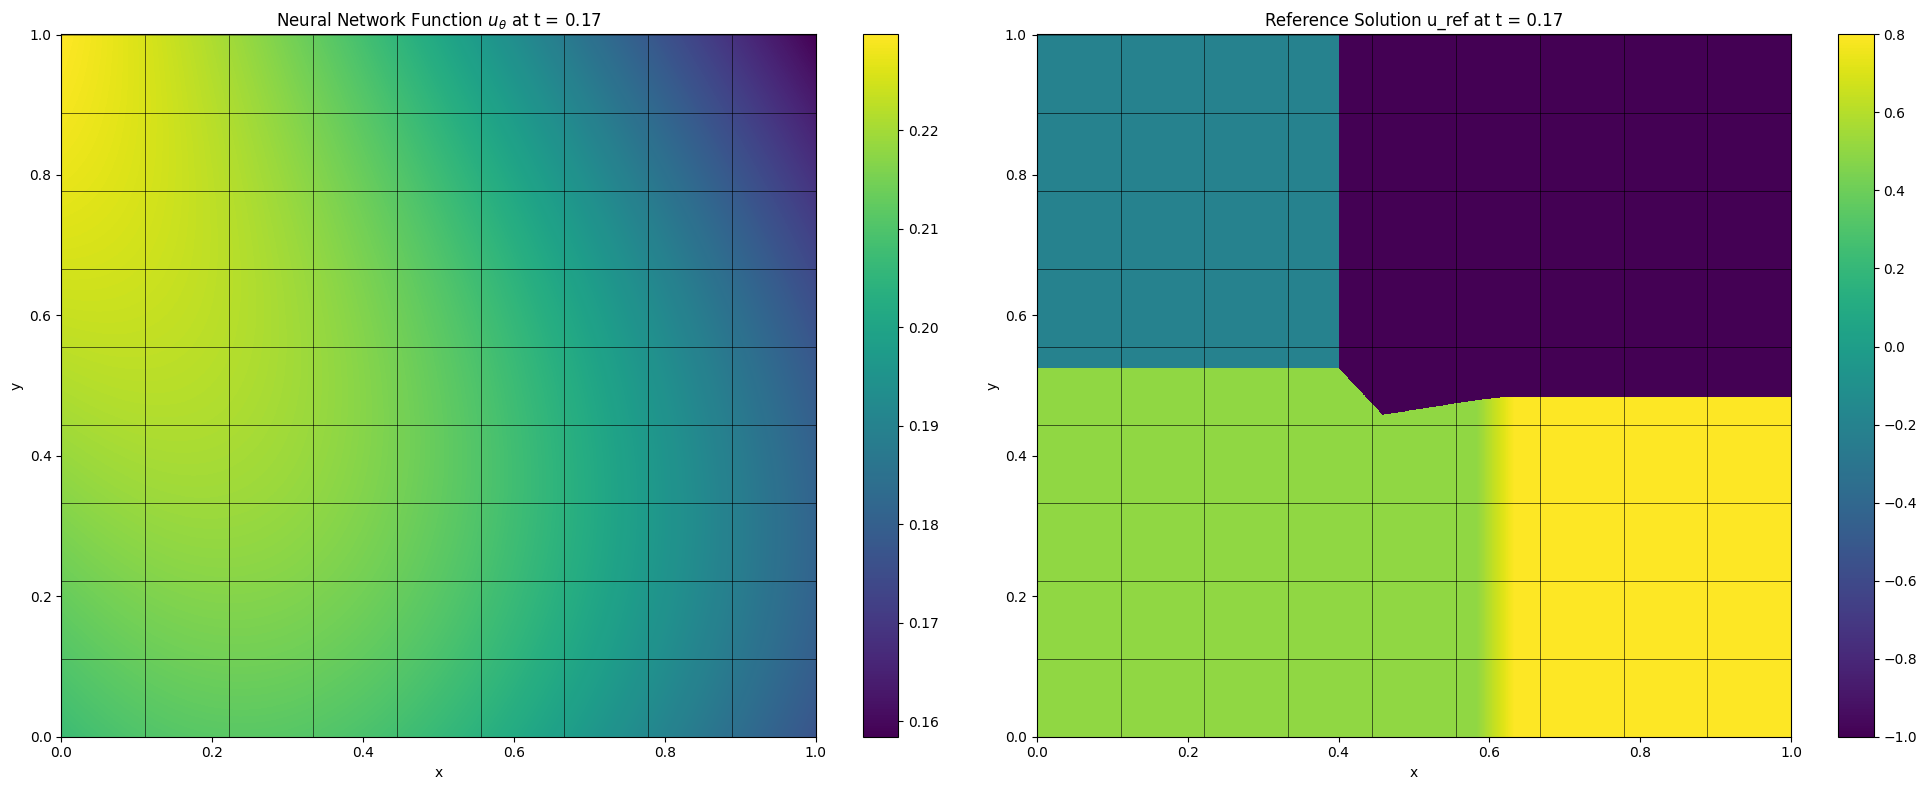

Grade 0, Iter 0, lambda_ic: 18.326757, lambda_bc: 18.147680, lambda_eqn: 6.844558
Grade 0, Iter 0, loss_eqn: 0.000209, loss_ibc: 2.542315


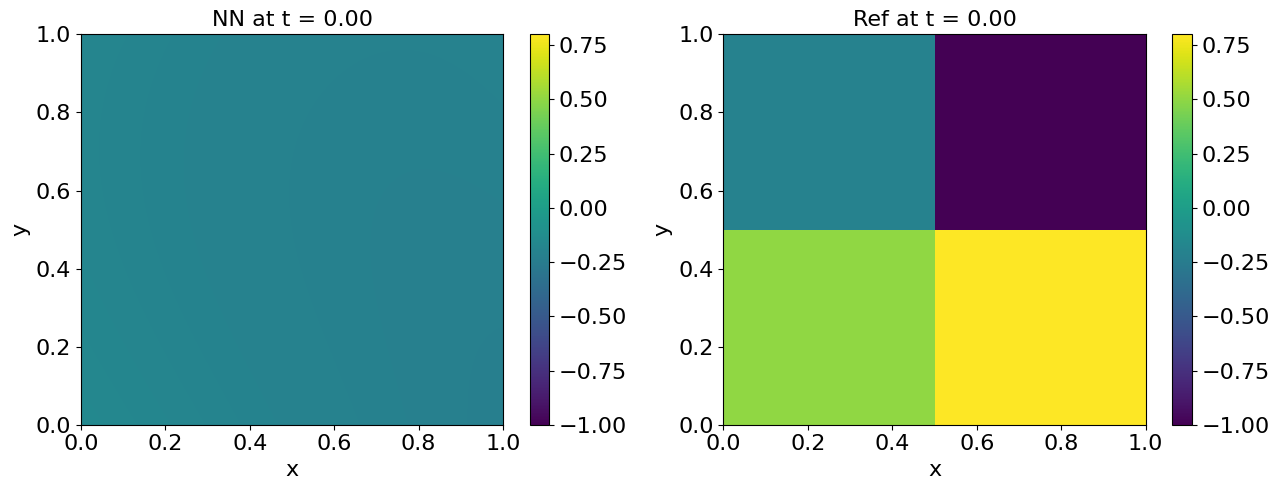

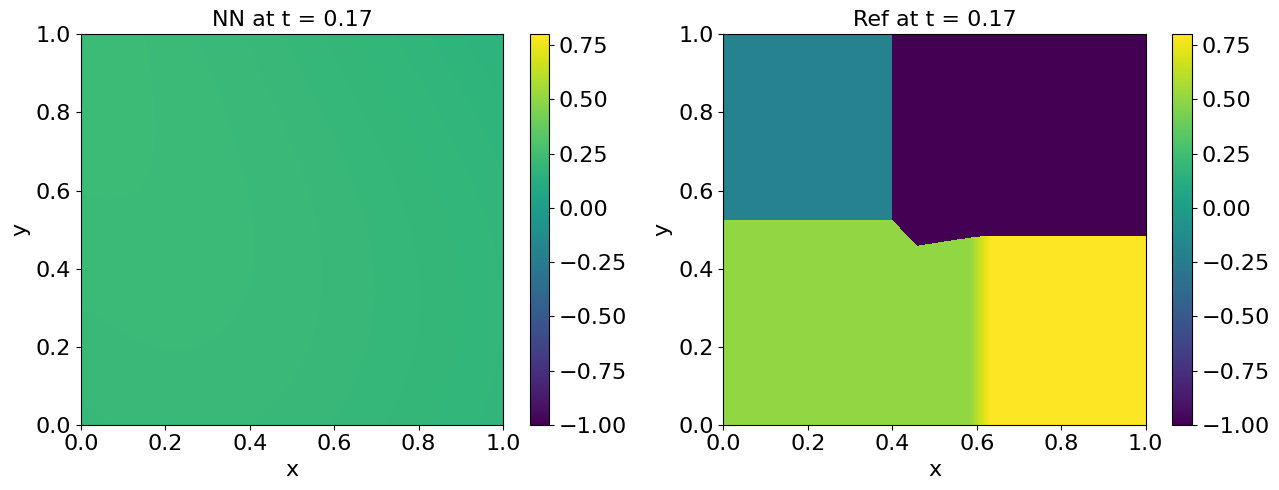

Grade 0, Iter 100, loss_eqn: 0.000028, loss_ibc: 0.504441
Grade 0, Iter 200, loss_eqn: 0.000051, loss_ibc: 0.120037
Grade 0, Iter 300, loss_eqn: 0.000049, loss_ibc: 0.051991
Grade 0, Iter 400, loss_eqn: 0.000054, loss_ibc: 0.028828
Grade 0, Iter 500, loss_eqn: 0.000044, loss_ibc: 0.017495
Grade 0, Iter 600, loss_eqn: 0.000040, loss_ibc: 0.011956
Grade 0, Iter 700, loss_eqn: 0.000034, loss_ibc: 0.008498
Grade 0, Iter 800, loss_eqn: 0.000031, loss_ibc: 0.006306
Grade 0, Iter 900, loss_eqn: 0.000029, loss_ibc: 0.005019
Grade 0, Iter 1000, loss_eqn: 0.000029, loss_ibc: 0.004228


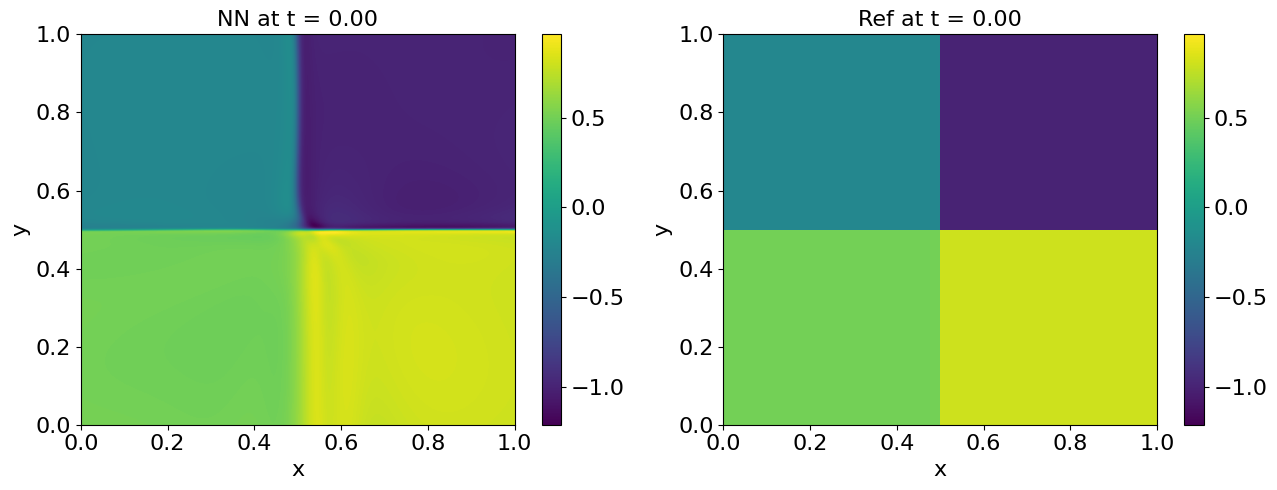

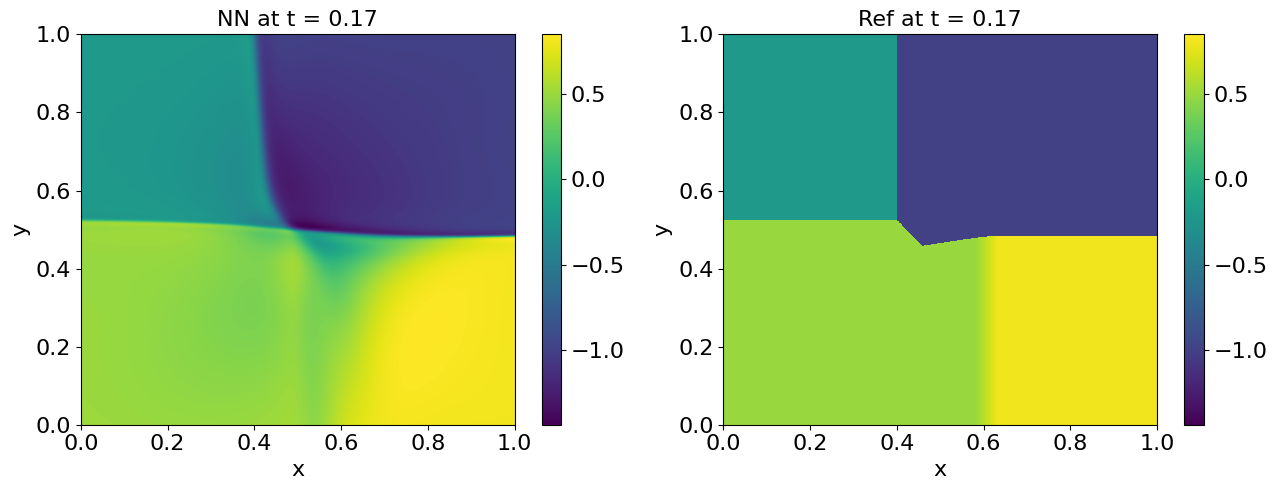

Grade 0, Iter 1100, loss_eqn: 0.000028, loss_ibc: 0.006188
Grade 0, Iter 1200, loss_eqn: 0.000028, loss_ibc: 0.003481
Grade 0, Iter 1300, loss_eqn: 0.000028, loss_ibc: 0.002691
Grade 0, Iter 1400, loss_eqn: 0.000029, loss_ibc: 0.002800
Grade 0, Iter 1500, loss_eqn: 0.000029, loss_ibc: 0.002212
Grade 0, Iter 1600, loss_eqn: 0.000030, loss_ibc: 0.001888
Grade 0, Iter 1700, loss_eqn: 0.000030, loss_ibc: 0.002245
Grade 0, Iter 1800, loss_eqn: 0.000032, loss_ibc: 0.001875
Grade 0, Iter 1900, loss_eqn: 0.000033, loss_ibc: 0.001472
Grade 0, Iter 2000, lambda_ic: 26.773708, lambda_bc: 18.422802, lambda_eqn: 6.266212
Grade 0, Iter 2000, loss_eqn: 0.000033, loss_ibc: 0.001515


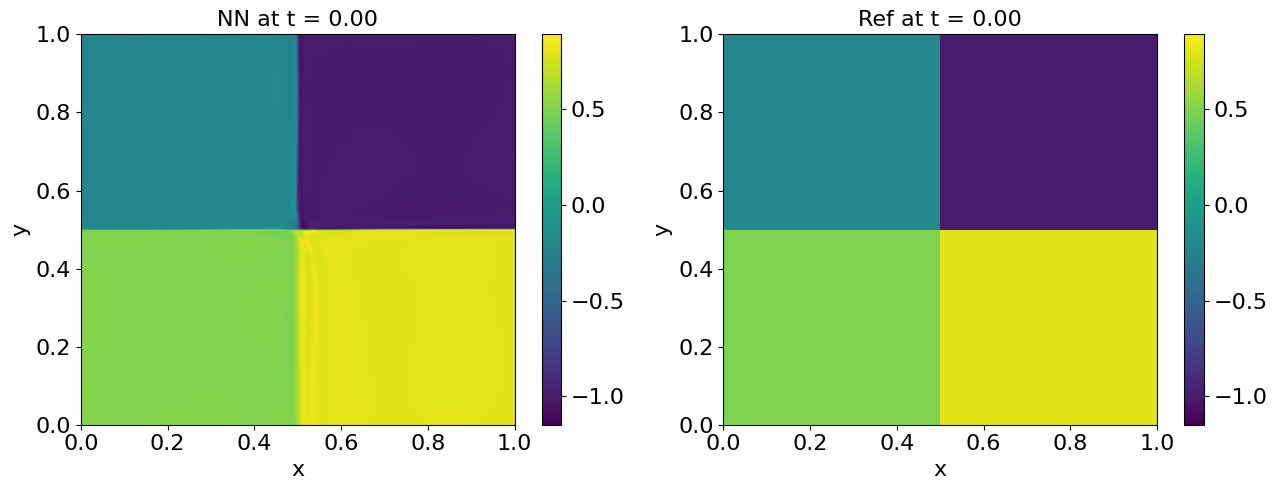

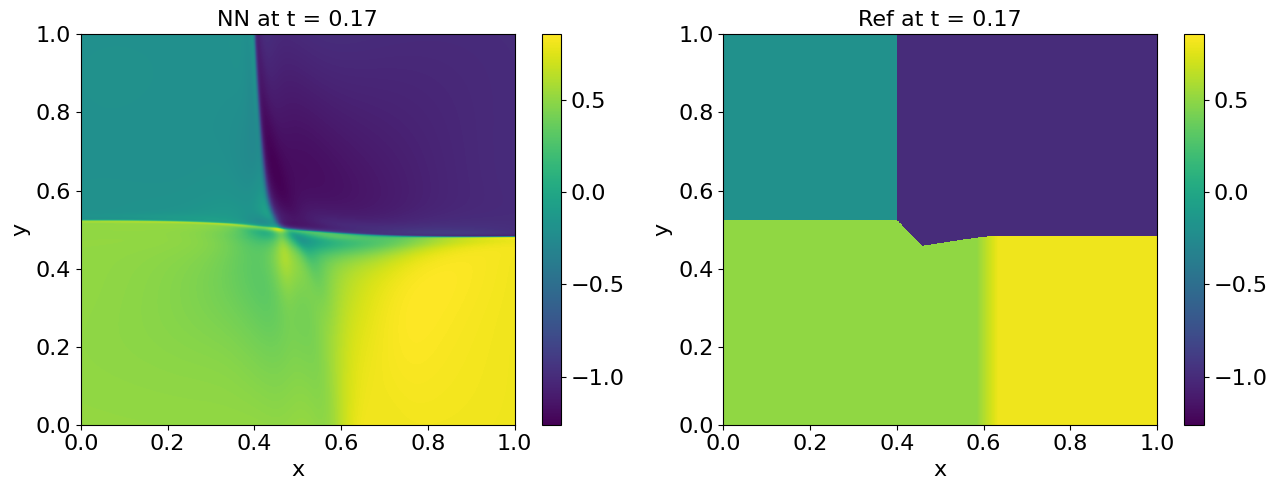

Grade 0, Iter 2100, loss_eqn: 0.000031, loss_ibc: 0.001282
Grade 0, Iter 2200, loss_eqn: 0.000033, loss_ibc: 0.001163
Grade 0, Iter 2300, loss_eqn: 0.000034, loss_ibc: 0.001077
Grade 0, Iter 2400, loss_eqn: 0.000035, loss_ibc: 0.001193
Grade 0, Iter 2500, loss_eqn: 0.000036, loss_ibc: 0.001044
Grade 0, Iter 2600, loss_eqn: 0.000036, loss_ibc: 0.000986
Grade 0, Iter 2700, loss_eqn: 0.000037, loss_ibc: 0.000938
Grade 0, Iter 2800, loss_eqn: 0.000037, loss_ibc: 0.000898
Grade 0, Iter 2900, loss_eqn: 0.000037, loss_ibc: 0.000876
Grade 0, Iter 3000, loss_eqn: 0.000037, loss_ibc: 0.000853


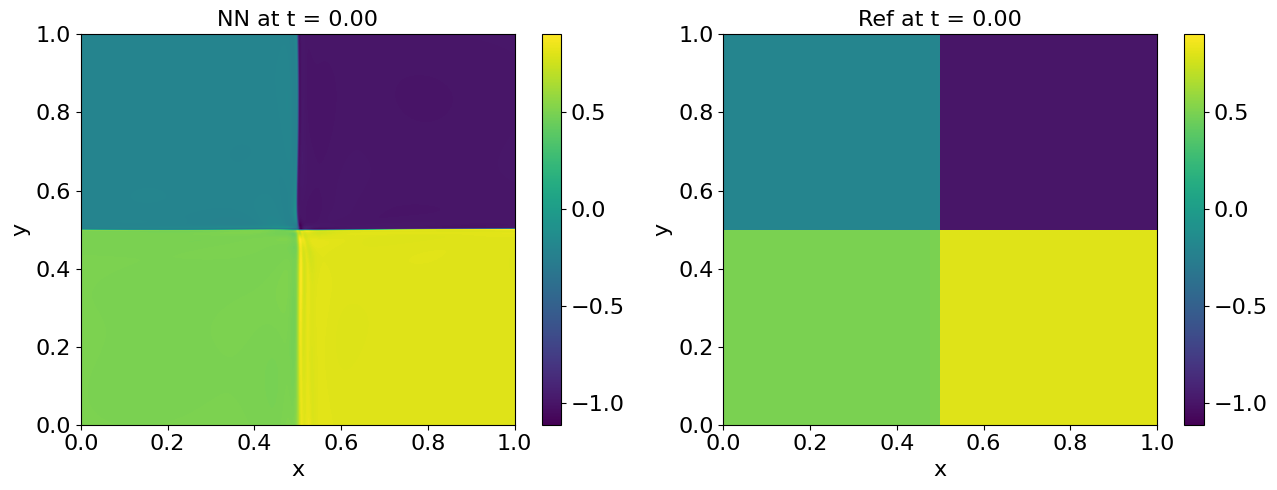

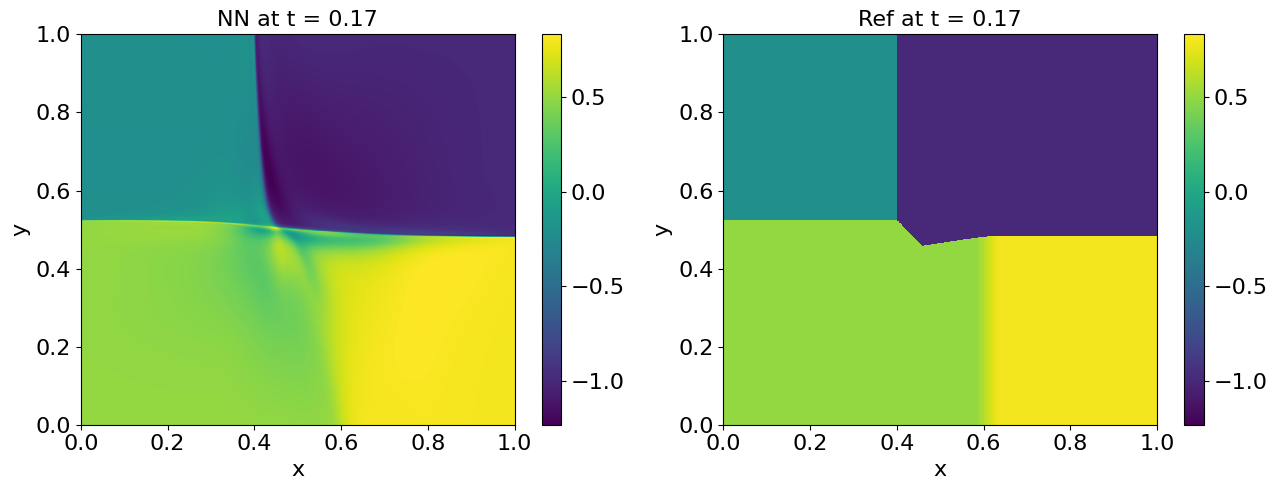

Grade 0, Iter 3100, loss_eqn: 0.000037, loss_ibc: 0.000817
Grade 0, Iter 3200, loss_eqn: 0.000037, loss_ibc: 0.000782
Grade 0, Iter 3300, loss_eqn: 0.000037, loss_ibc: 0.000749
Grade 0, Iter 3400, loss_eqn: 0.000036, loss_ibc: 0.000718
Grade 0, Iter 3500, loss_eqn: 0.000036, loss_ibc: 0.000689
Grade 0, Iter 3600, loss_eqn: 0.000036, loss_ibc: 0.000661
Grade 0, Iter 3700, loss_eqn: 0.000036, loss_ibc: 0.000634
Grade 0, Iter 3800, loss_eqn: 0.000036, loss_ibc: 0.000608
Grade 0, Iter 3900, loss_eqn: 0.000036, loss_ibc: 0.000583
Grade 0, Iter 4000, lambda_ic: 113.166031, lambda_bc: 25.063507, lambda_eqn: 5.740899
Grade 0, Iter 4000, loss_eqn: 0.000039, loss_ibc: 0.000559


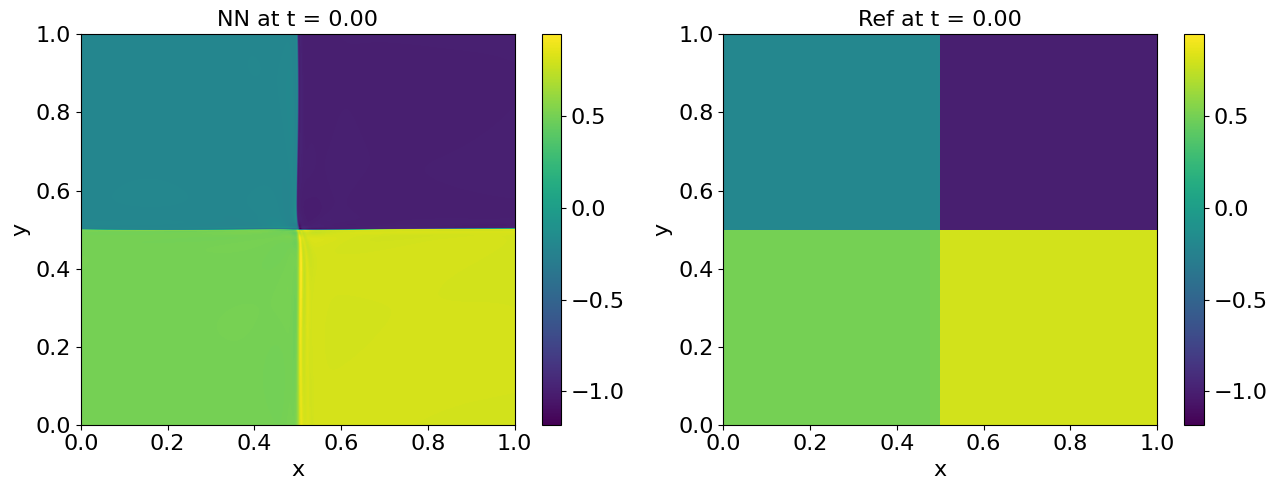

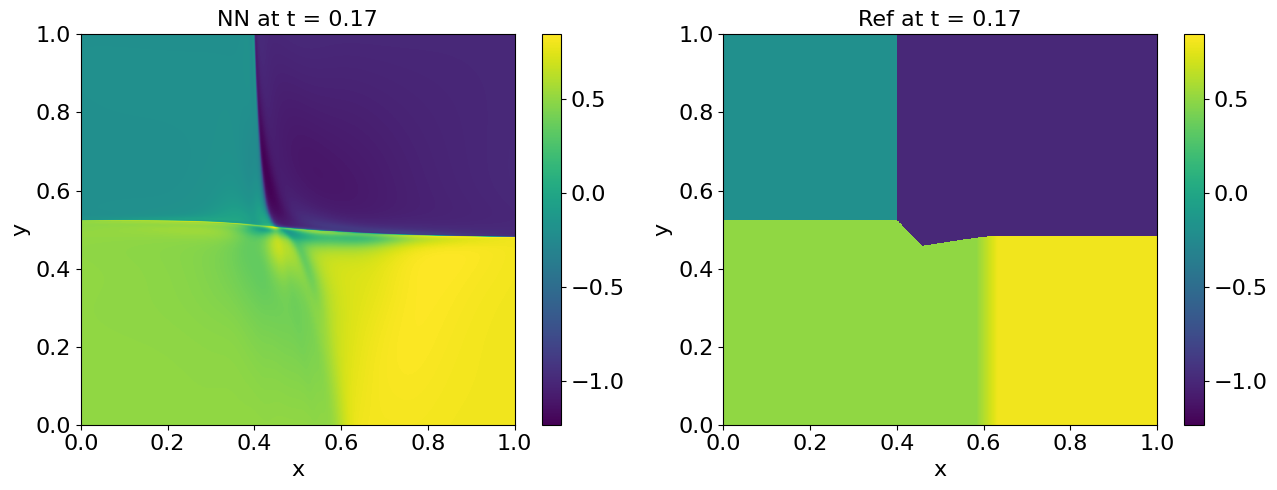

Grade 0, Iter 4100, loss_eqn: 0.000027, loss_ibc: 0.002188
Grade 0, Iter 4200, loss_eqn: 0.000030, loss_ibc: 0.001345
Grade 0, Iter 4300, loss_eqn: 0.000032, loss_ibc: 0.001104
Grade 0, Iter 4400, loss_eqn: 0.000033, loss_ibc: 0.000957
Grade 0, Iter 4500, loss_eqn: 0.000034, loss_ibc: 0.000842
Grade 0, Iter 4600, loss_eqn: 0.000035, loss_ibc: 0.000743
Grade 0, Iter 4700, loss_eqn: 0.000036, loss_ibc: 0.000673
Grade 0, Iter 4800, loss_eqn: 0.000037, loss_ibc: 0.000617
Grade 0, Iter 4900, loss_eqn: 0.000038, loss_ibc: 0.000570
Grade 0, Iter 5000, loss_eqn: 0.000039, loss_ibc: 0.000532


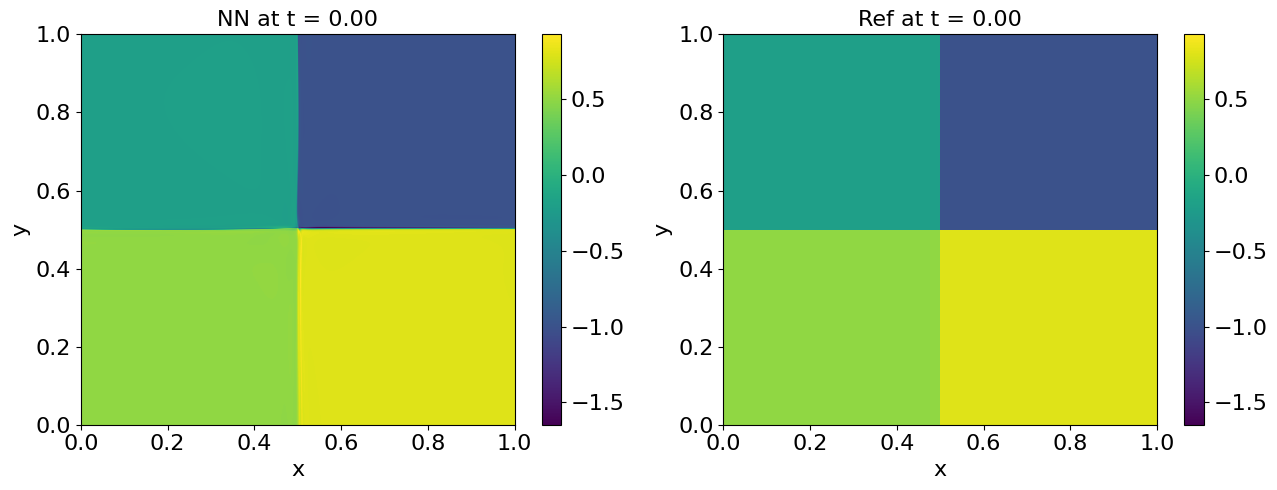

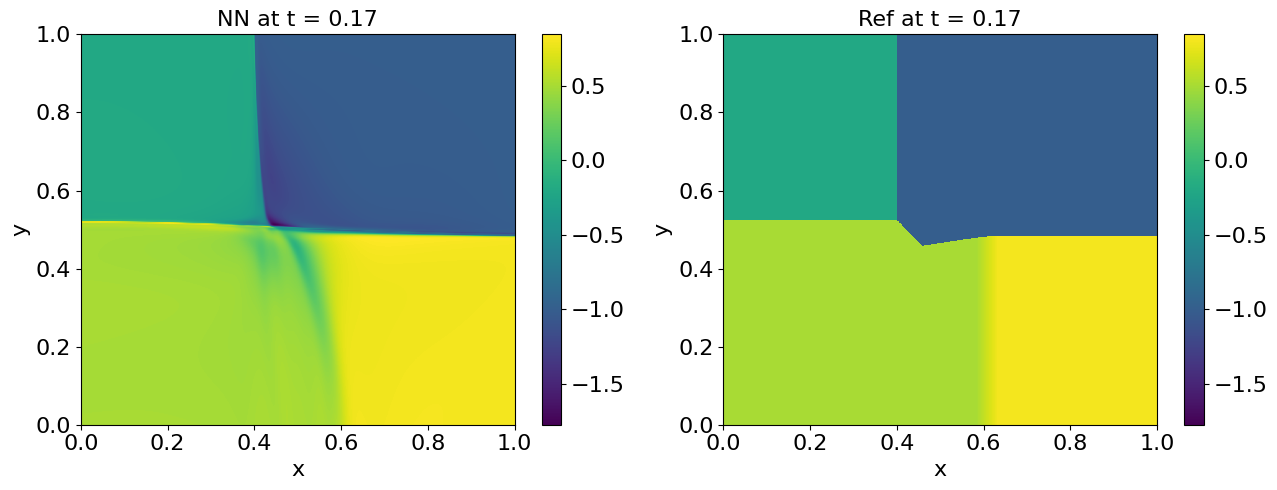

Grade 0, Iter 5100, loss_eqn: 0.000039, loss_ibc: 0.000507
Grade 0, Iter 5200, loss_eqn: 0.000039, loss_ibc: 0.000472
Grade 0, Iter 5300, loss_eqn: 0.000040, loss_ibc: 0.000441
Grade 0, Iter 5400, loss_eqn: 0.000040, loss_ibc: 0.000417
Grade 0, Iter 5500, loss_eqn: 0.000040, loss_ibc: 0.000412
Grade 0, Iter 5600, loss_eqn: 0.000040, loss_ibc: 0.000389
Grade 0, Iter 5700, loss_eqn: 0.000041, loss_ibc: 0.000373
Grade 0, Iter 5800, loss_eqn: 0.000041, loss_ibc: 0.000338
Grade 0, Iter 5900, loss_eqn: 0.000041, loss_ibc: 0.000324
Grade 0, Iter 6000, lambda_ic: 176.777863, lambda_bc: 47.326939, lambda_eqn: 5.267349
Grade 0, Iter 6000, loss_eqn: 0.000042, loss_ibc: 0.000312


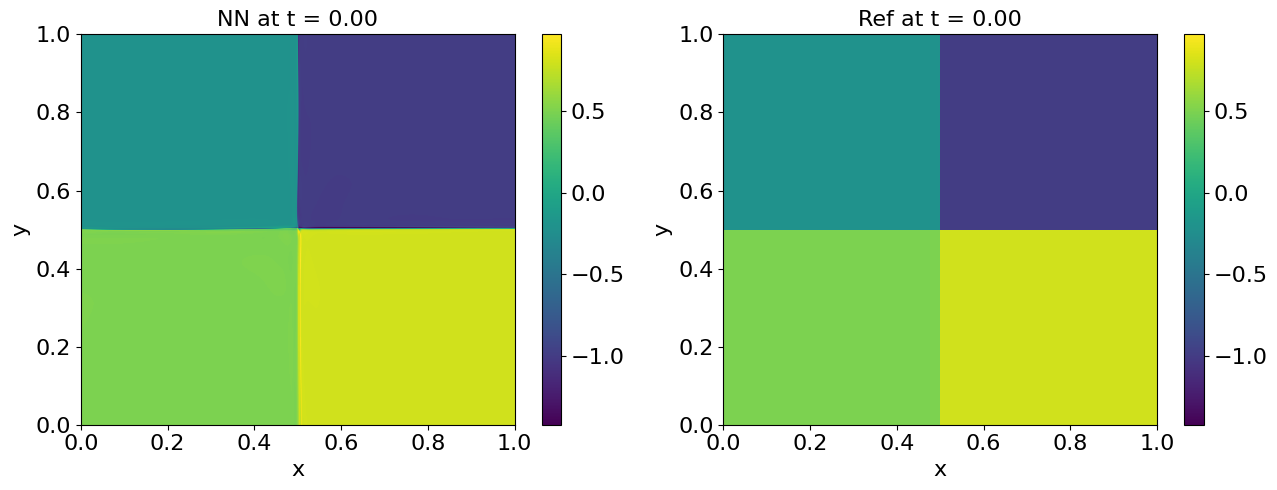

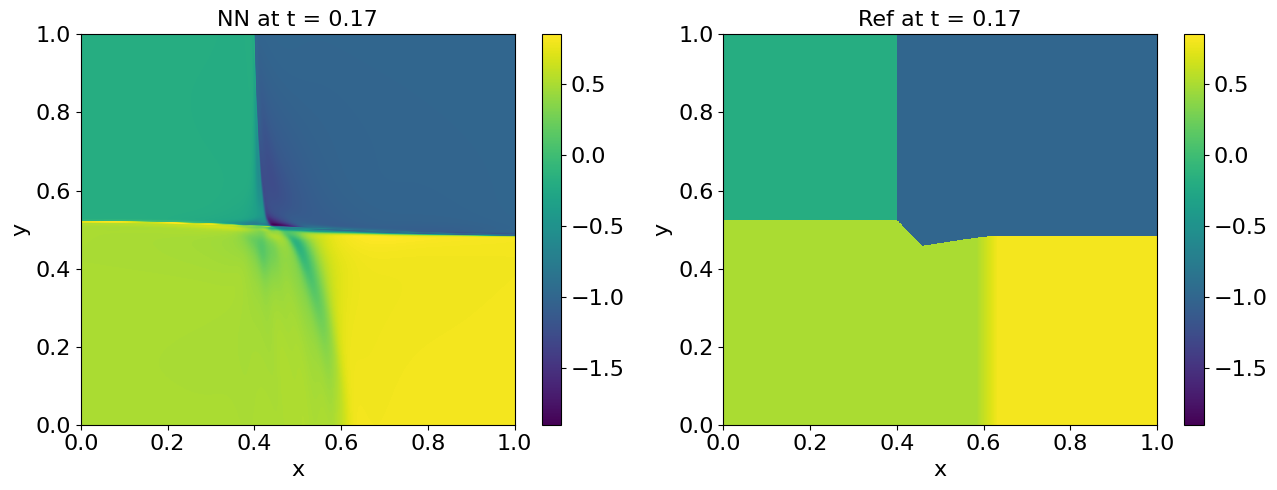

Grade 0, Iter 6100, loss_eqn: 0.000043, loss_ibc: 0.000629
Grade 0, Iter 6200, loss_eqn: 0.000045, loss_ibc: 0.000483
Grade 0, Iter 6300, loss_eqn: 0.000045, loss_ibc: 0.000424
Grade 0, Iter 6400, loss_eqn: 0.000046, loss_ibc: 0.000387
Grade 0, Iter 6500, loss_eqn: 0.000046, loss_ibc: 0.000360
Grade 0, Iter 6600, loss_eqn: 0.000047, loss_ibc: 0.000337
Grade 0, Iter 6700, loss_eqn: 0.000047, loss_ibc: 0.000317
Grade 0, Iter 6800, loss_eqn: 0.000047, loss_ibc: 0.000299
Grade 0, Iter 6900, loss_eqn: 0.000048, loss_ibc: 0.000282
Grade 0, Iter 7000, loss_eqn: 0.000048, loss_ibc: 0.000268


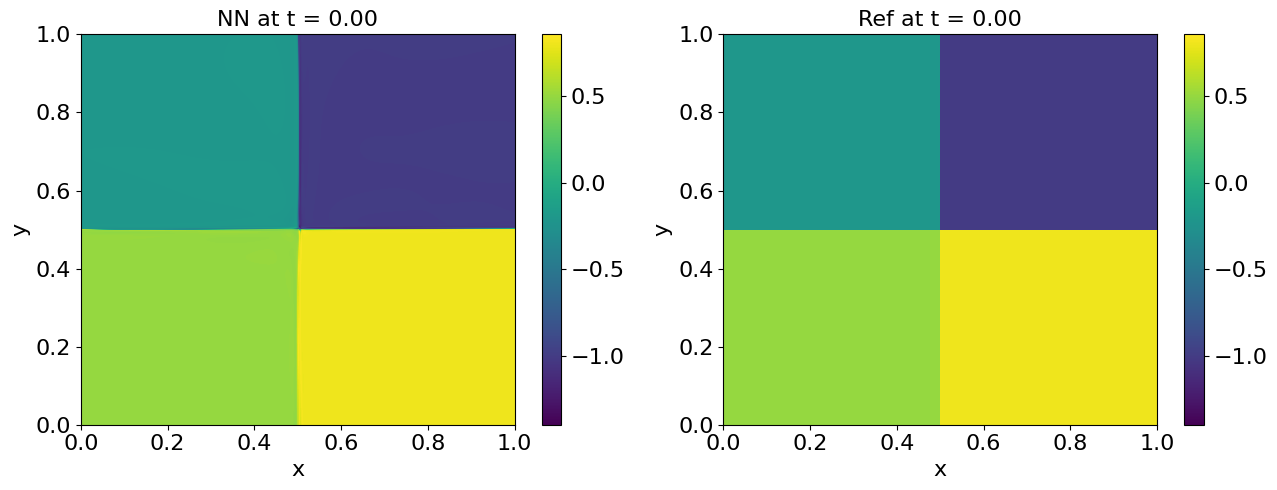

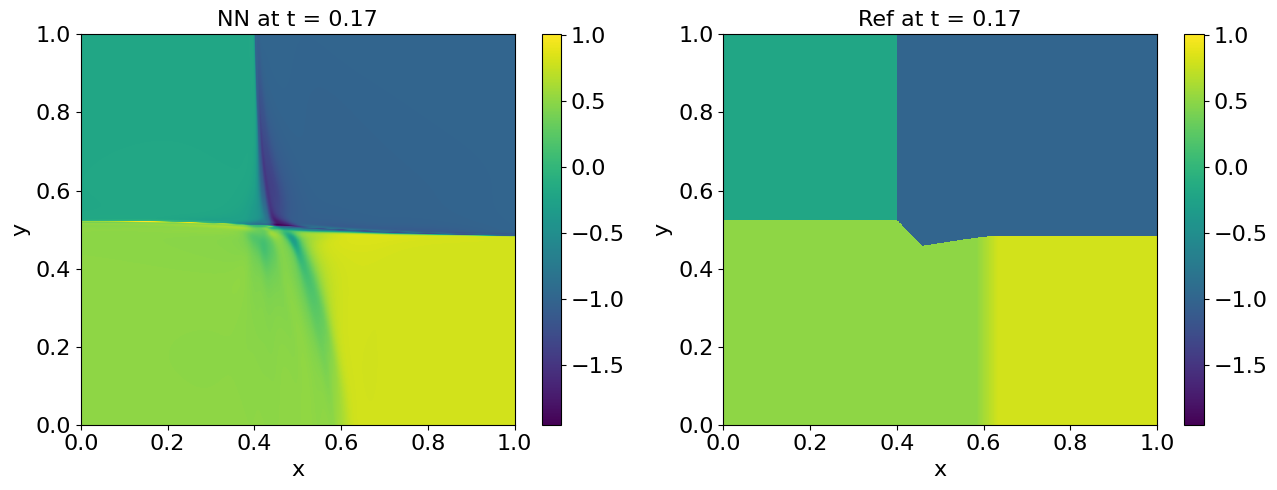

Grade 0, Iter 7100, loss_eqn: 0.000048, loss_ibc: 0.000254
Grade 0, Iter 7200, loss_eqn: 0.000048, loss_ibc: 0.000242
Grade 0, Iter 7300, loss_eqn: 0.000048, loss_ibc: 0.000231
Grade 0, Iter 7400, loss_eqn: 0.000048, loss_ibc: 0.000221
Grade 0, Iter 7500, loss_eqn: 0.000048, loss_ibc: 0.000211
Grade 0, Iter 7600, loss_eqn: 0.000049, loss_ibc: 0.000203
Grade 0, Iter 7700, loss_eqn: 0.000049, loss_ibc: 0.000195
Grade 0, Iter 7800, loss_eqn: 0.000049, loss_ibc: 0.000188
Grade 0, Iter 7900, loss_eqn: 0.000049, loss_ibc: 0.000182
Grade 0, Iter 8000, lambda_ic: 6581.158203, lambda_bc: 657.513855, lambda_eqn: 4.840632
Grade 0, Iter 8000, loss_eqn: 0.000049, loss_ibc: 0.000176


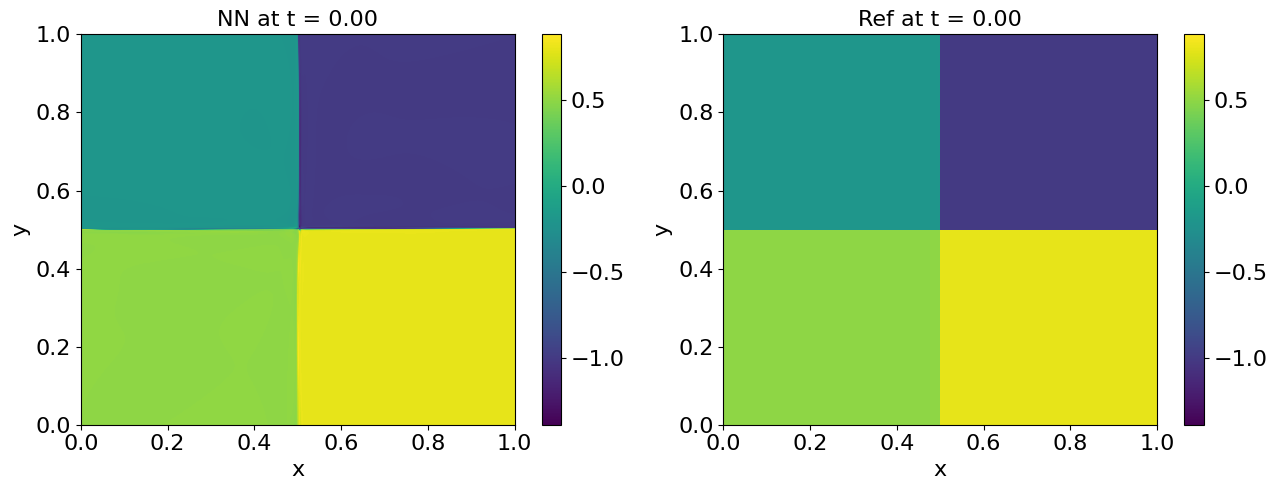

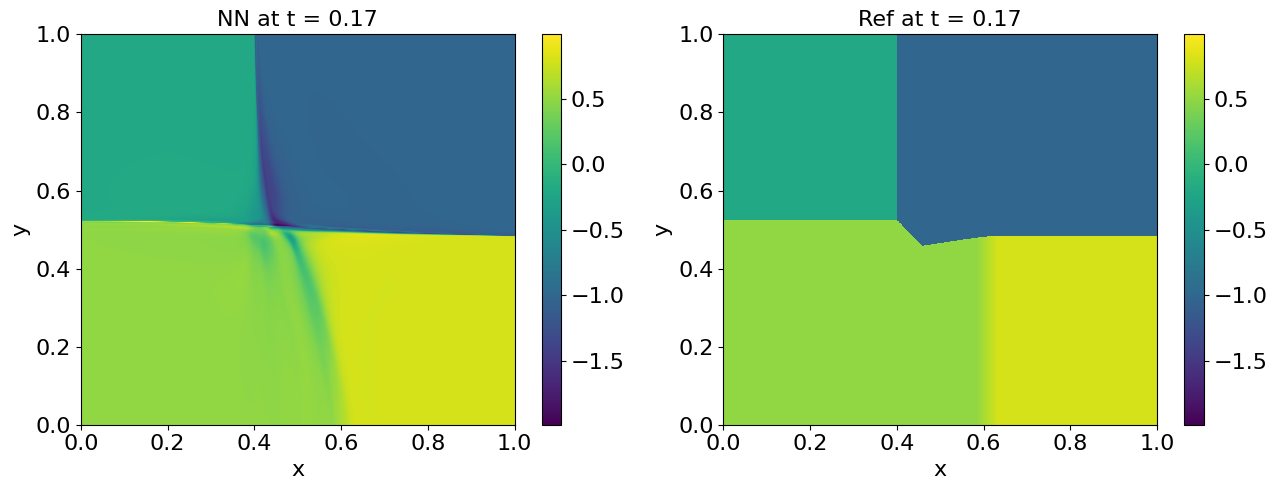

Grade 0, Iter 8100, loss_eqn: 0.000039, loss_ibc: 0.000387
Grade 0, Iter 8200, loss_eqn: 0.000040, loss_ibc: 0.000273
Grade 0, Iter 8300, loss_eqn: 0.000040, loss_ibc: 0.000240
Grade 0, Iter 8400, loss_eqn: 0.000040, loss_ibc: 0.000222
Grade 0, Iter 8500, loss_eqn: 0.000041, loss_ibc: 0.000209
Grade 0, Iter 8600, loss_eqn: 0.000041, loss_ibc: 0.000200
Grade 0, Iter 8700, loss_eqn: 0.000041, loss_ibc: 0.000193
Grade 0, Iter 8800, loss_eqn: 0.000041, loss_ibc: 0.000187
Grade 0, Iter 8900, loss_eqn: 0.000041, loss_ibc: 0.000182
Grade 0, Iter 9000, loss_eqn: 0.000041, loss_ibc: 0.000178


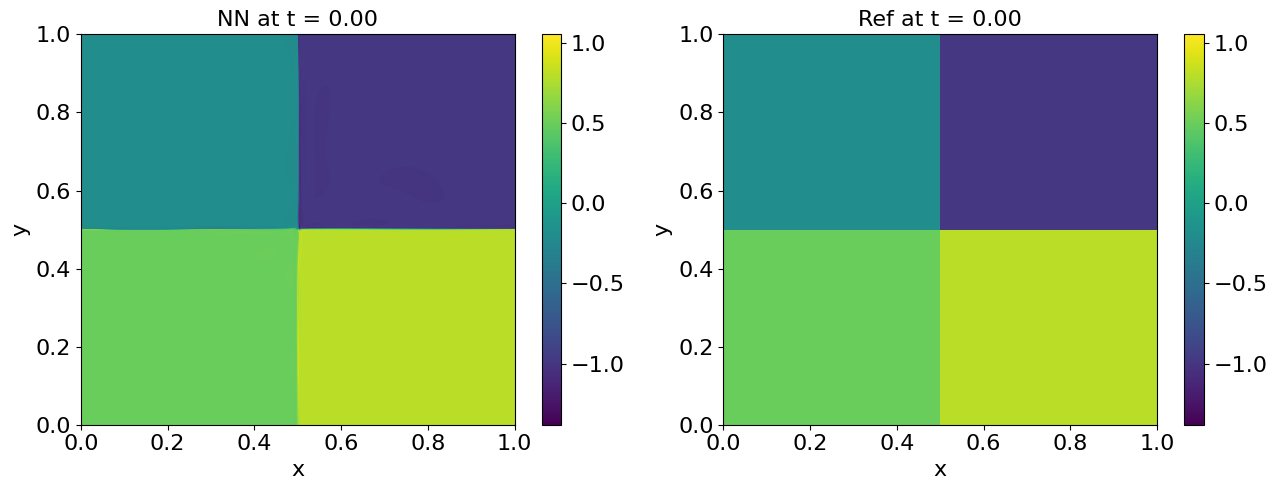

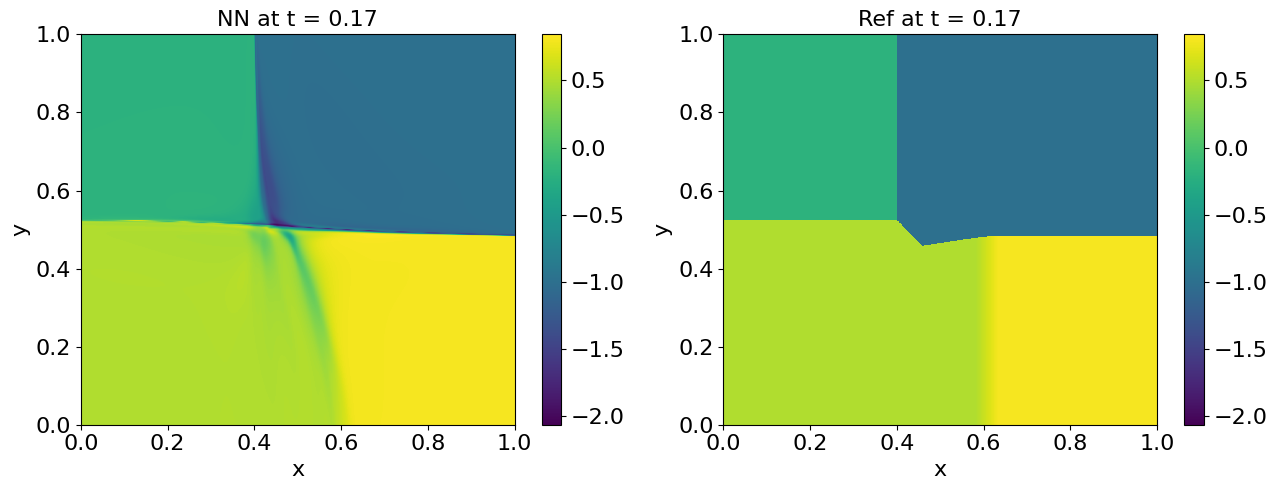

Grade 0, Iter 9100, loss_eqn: 0.000041, loss_ibc: 0.000175
Grade 0, Iter 9200, loss_eqn: 0.000041, loss_ibc: 0.000172
Grade 0, Iter 9300, loss_eqn: 0.000041, loss_ibc: 0.000169
Grade 0, Iter 9400, loss_eqn: 0.000042, loss_ibc: 0.000167
Grade 0, Iter 9500, loss_eqn: 0.000042, loss_ibc: 0.000165
Grade 0, Iter 9600, loss_eqn: 0.000042, loss_ibc: 0.000163
Grade 0, Iter 9700, loss_eqn: 0.000042, loss_ibc: 0.000162
Grade 0, Iter 9800, loss_eqn: 0.000042, loss_ibc: 0.000160
Grade 0, Iter 9900, loss_eqn: 0.000042, loss_ibc: 0.000159
Train time for stage1: 14661.511001 seconds

Plotting after training segment [0.0000, 0.1667]


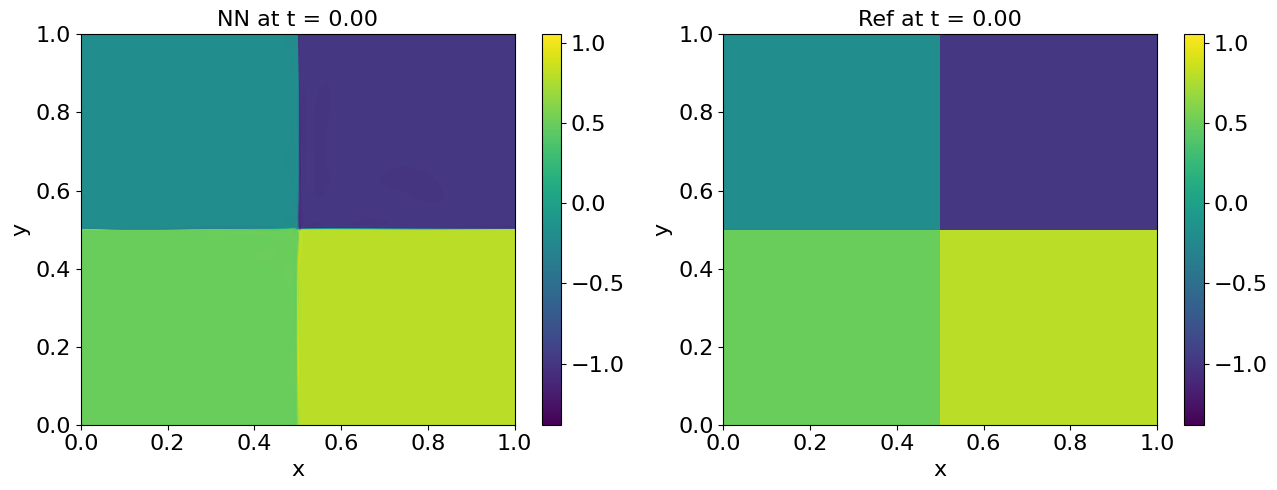

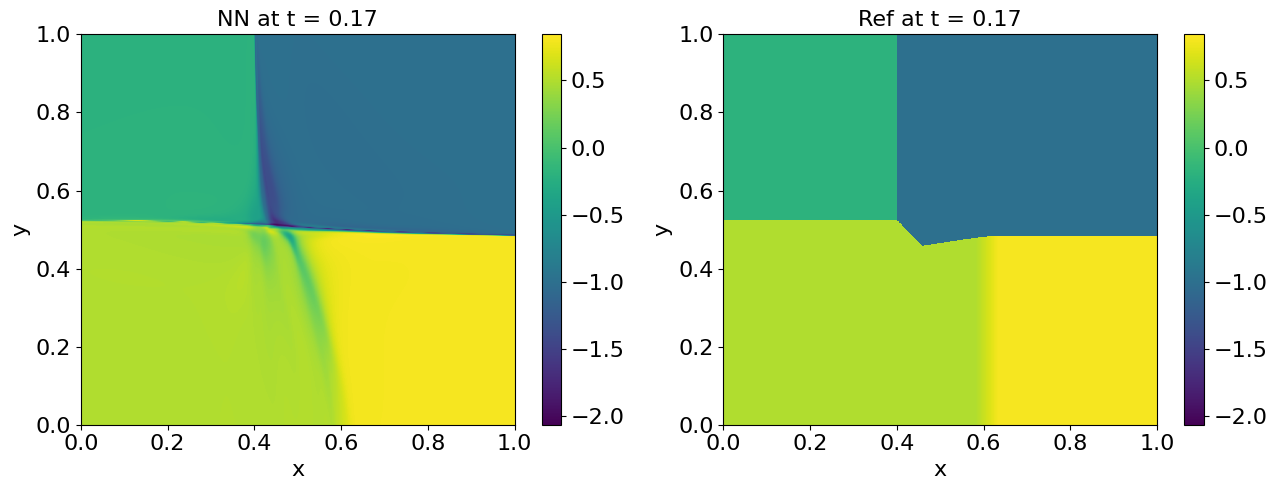

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]
Partition type: hex, dg_type: Q1, p_dof: 8

Training segment [0.1667, 0.3333]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0


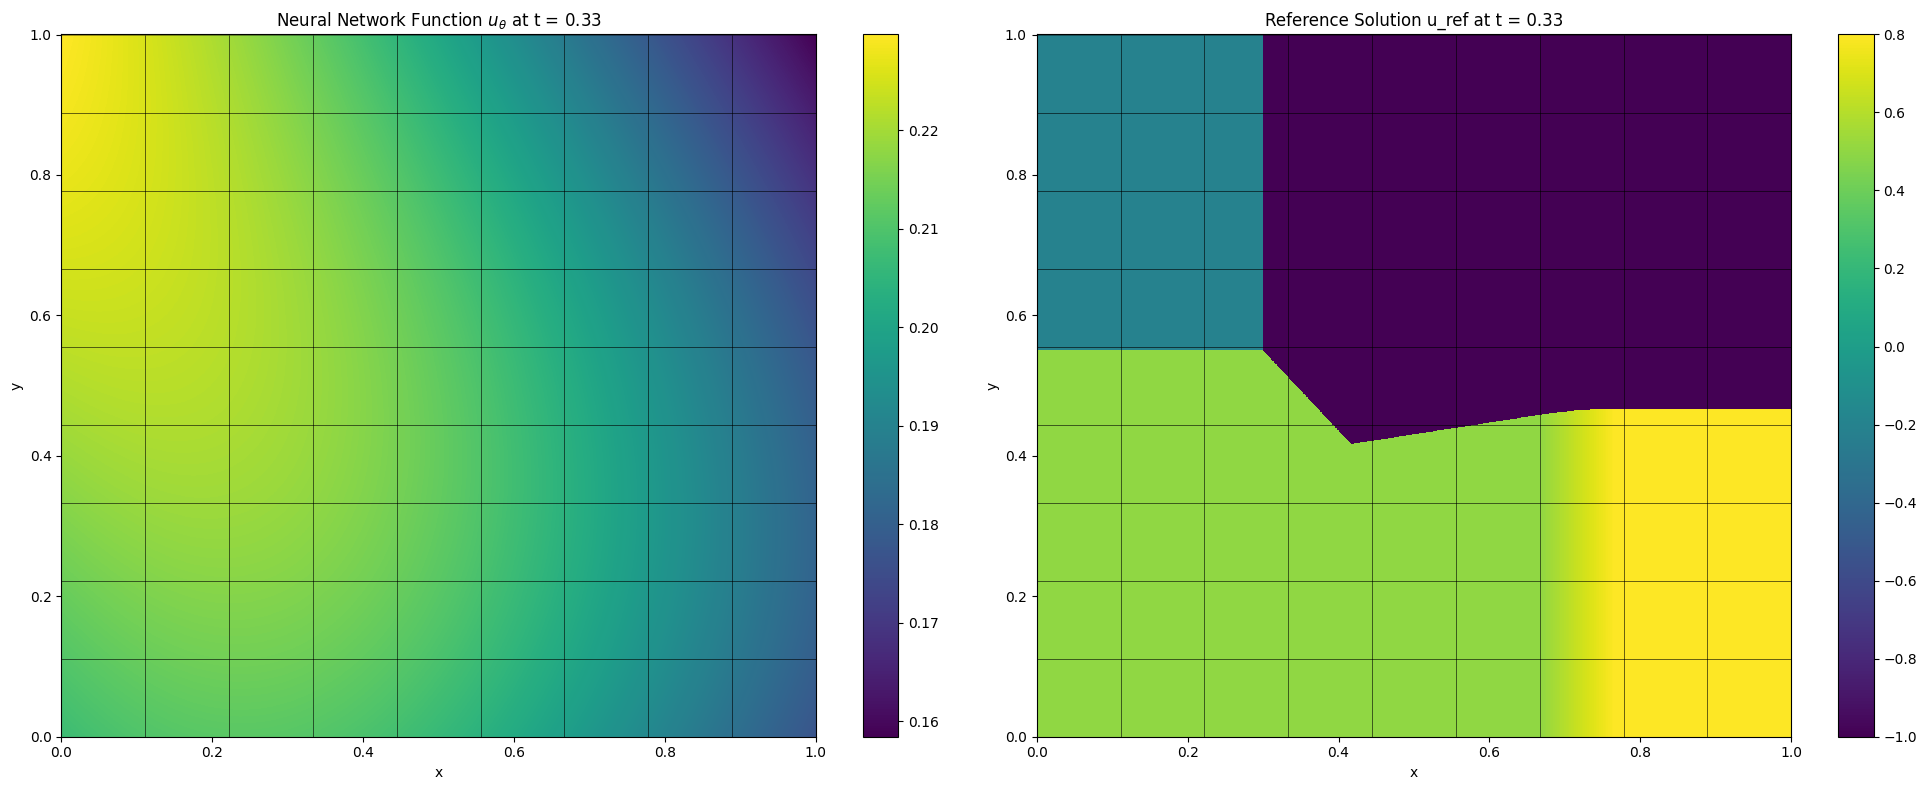

Grade 0, Iter 0, lambda_ic: 18.410301, lambda_bc: 18.135450, lambda_eqn: 6.454698
Grade 0, Iter 0, loss_eqn: 0.000209, loss_ibc: 2.618299


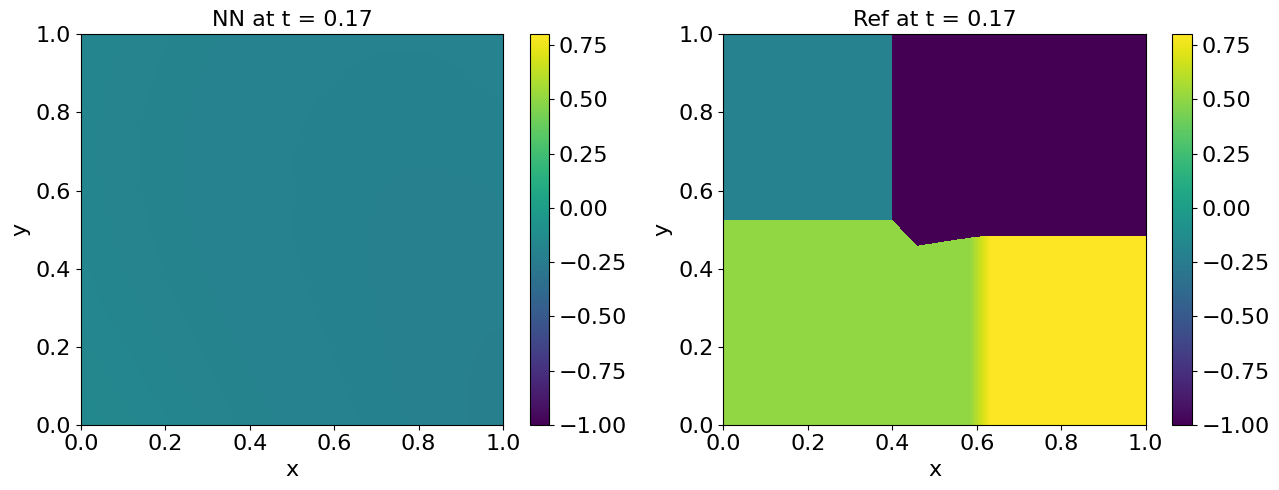

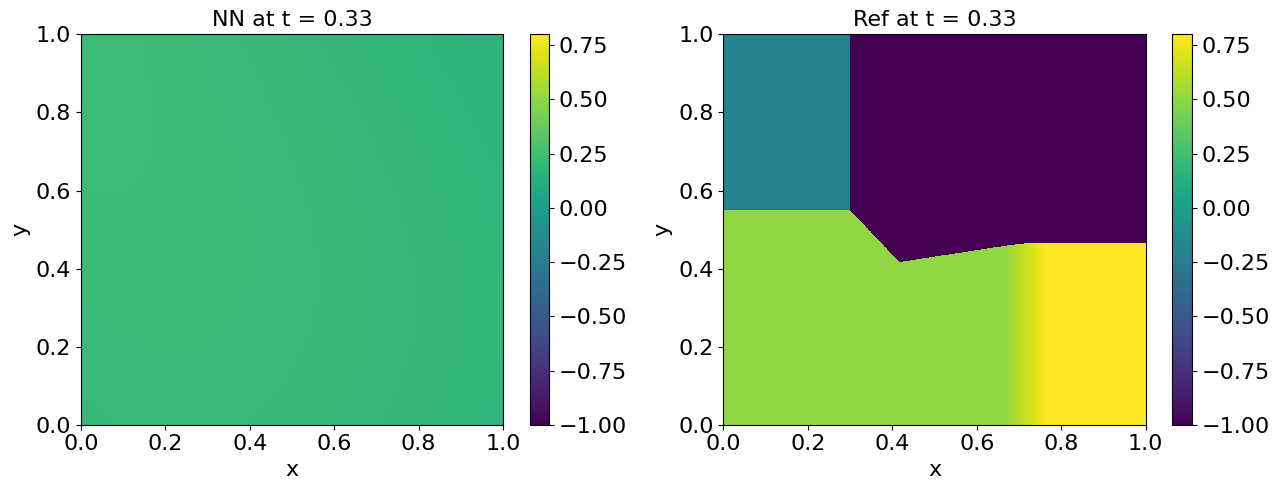

Grade 0, Iter 100, loss_eqn: 0.000057, loss_ibc: 0.456527
Grade 0, Iter 200, loss_eqn: 0.000083, loss_ibc: 0.125672
Grade 0, Iter 300, loss_eqn: 0.000082, loss_ibc: 0.065824
Grade 0, Iter 400, loss_eqn: 0.000109, loss_ibc: 0.032397
Grade 0, Iter 500, loss_eqn: 0.000077, loss_ibc: 0.019268
Grade 0, Iter 600, loss_eqn: 0.000070, loss_ibc: 0.012282
Grade 0, Iter 700, loss_eqn: 0.000056, loss_ibc: 0.008596
Grade 0, Iter 800, loss_eqn: 0.000049, loss_ibc: 0.006283
Grade 0, Iter 900, loss_eqn: 0.000046, loss_ibc: 0.006668
Grade 0, Iter 1000, loss_eqn: 0.000042, loss_ibc: 0.004258


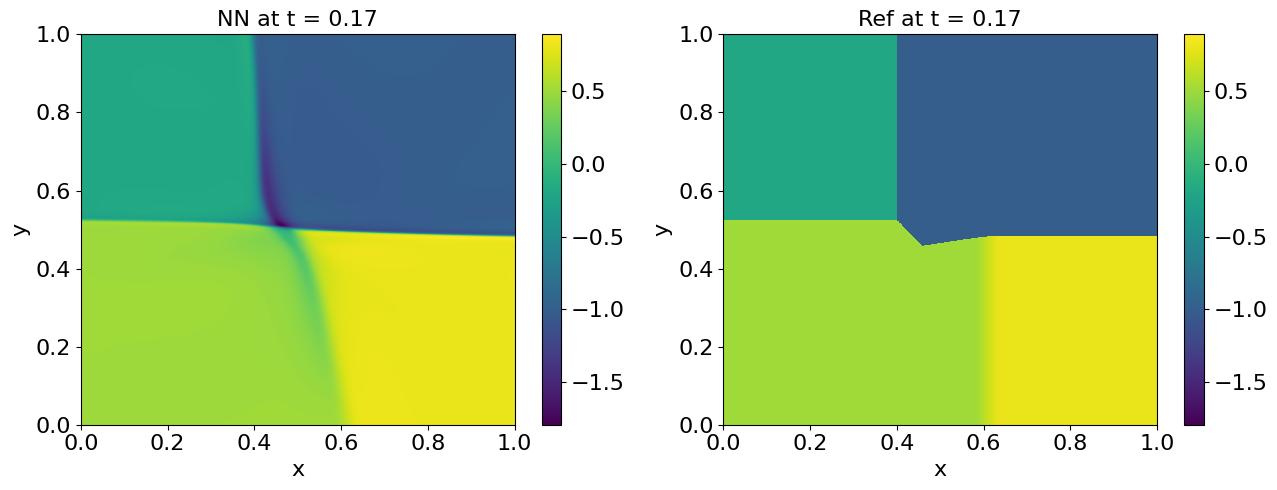

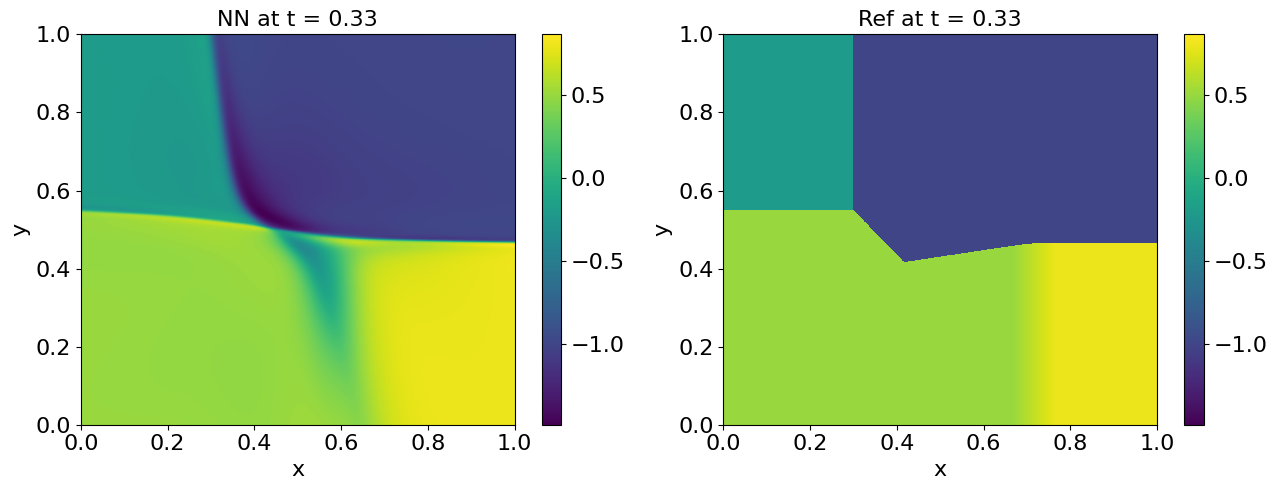

Grade 0, Iter 1100, loss_eqn: 0.000041, loss_ibc: 0.003554
Grade 0, Iter 1200, loss_eqn: 0.000041, loss_ibc: 0.003299
Grade 0, Iter 1300, loss_eqn: 0.000038, loss_ibc: 0.005619
Grade 0, Iter 1400, loss_eqn: 0.000041, loss_ibc: 0.002684
Grade 0, Iter 1500, loss_eqn: 0.000040, loss_ibc: 0.002388
Grade 0, Iter 1600, loss_eqn: 0.000040, loss_ibc: 0.002282
Grade 0, Iter 1700, loss_eqn: 0.000039, loss_ibc: 0.003234
Grade 0, Iter 1800, loss_eqn: 0.000040, loss_ibc: 0.001961
Grade 0, Iter 1900, loss_eqn: 0.000039, loss_ibc: 0.002040
Grade 0, Iter 2000, lambda_ic: 22.148895, lambda_bc: 18.168457, lambda_eqn: 5.916996
Grade 0, Iter 2000, loss_eqn: 0.000038, loss_ibc: 0.001871


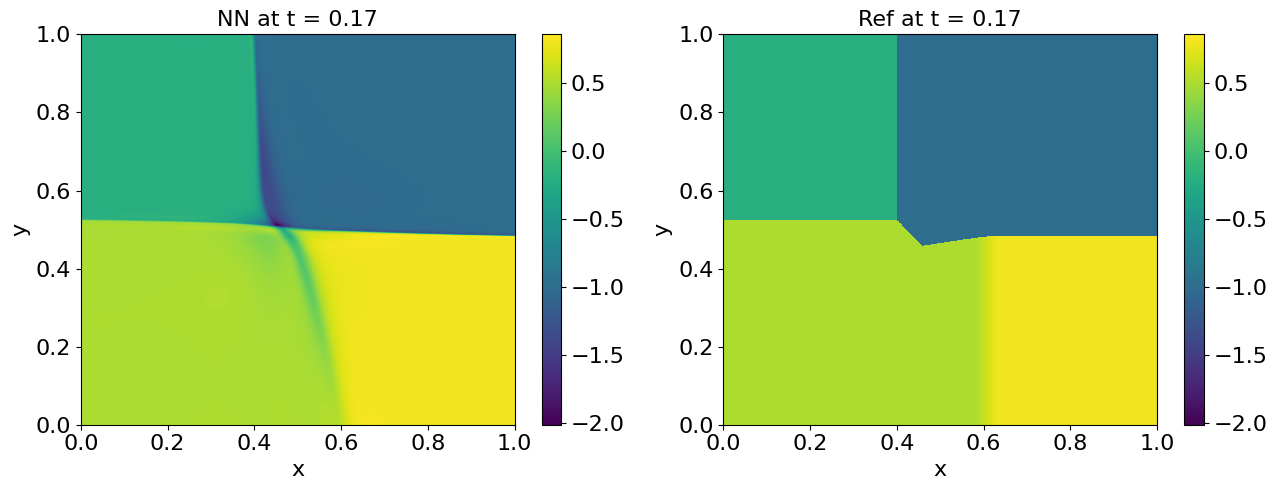

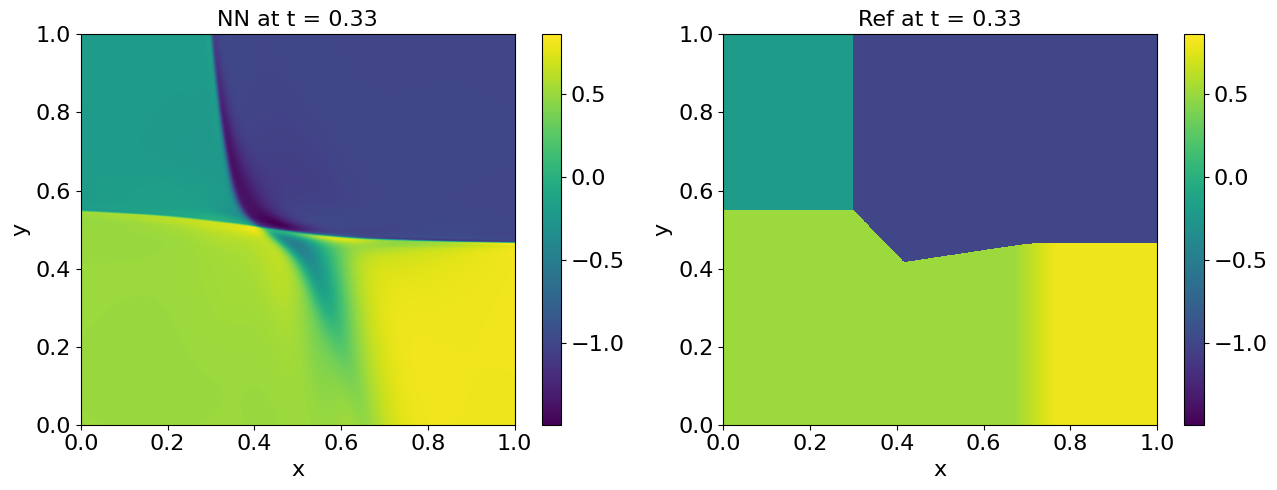

Grade 0, Iter 2100, loss_eqn: 0.000037, loss_ibc: 0.001778
Grade 0, Iter 2200, loss_eqn: 0.000036, loss_ibc: 0.001675
Grade 0, Iter 2300, loss_eqn: 0.000035, loss_ibc: 0.001645
Grade 0, Iter 2400, loss_eqn: 0.000035, loss_ibc: 0.001530
Grade 0, Iter 2500, loss_eqn: 0.000034, loss_ibc: 0.001471
Grade 0, Iter 2600, loss_eqn: 0.000034, loss_ibc: 0.001428
Grade 0, Iter 2700, loss_eqn: 0.000034, loss_ibc: 0.001337
Grade 0, Iter 2800, loss_eqn: 0.000034, loss_ibc: 0.001280
Grade 0, Iter 2900, loss_eqn: 0.000033, loss_ibc: 0.001231
Grade 0, Iter 3000, loss_eqn: 0.000034, loss_ibc: 0.001225


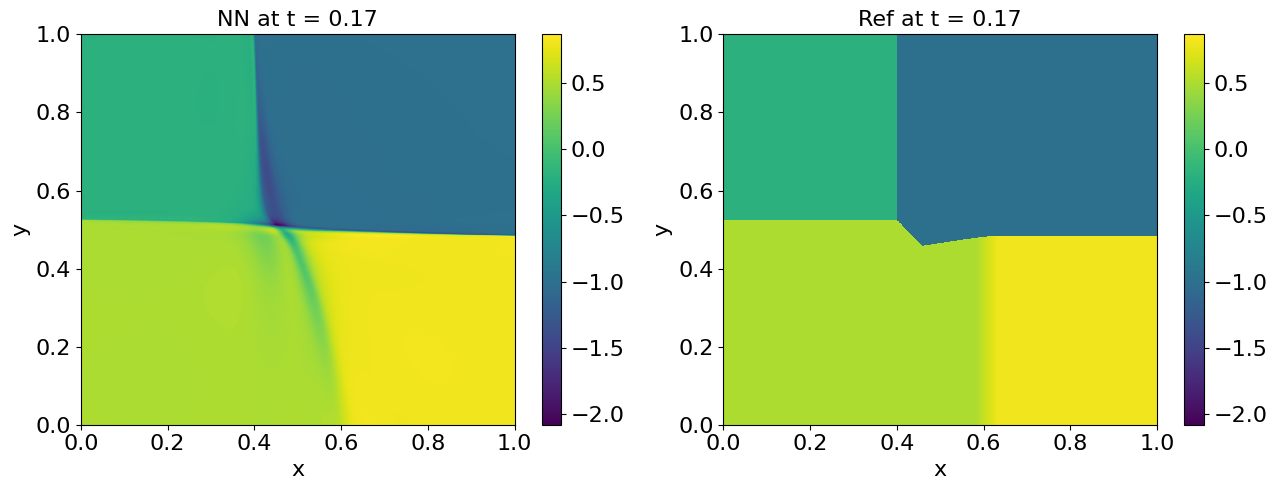

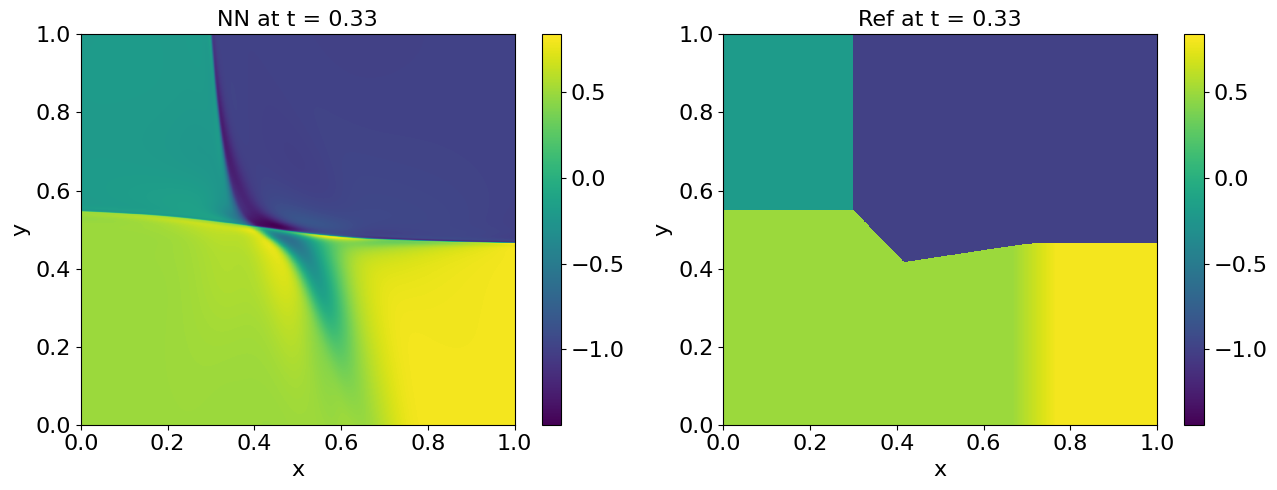

Grade 0, Iter 3100, loss_eqn: 0.000033, loss_ibc: 0.001190
Grade 0, Iter 3200, loss_eqn: 0.000033, loss_ibc: 0.001083
Grade 0, Iter 3300, loss_eqn: 0.000033, loss_ibc: 0.000977
Grade 0, Iter 3400, loss_eqn: 0.000033, loss_ibc: 0.001025
Grade 0, Iter 3500, loss_eqn: 0.000033, loss_ibc: 0.000946
Grade 0, Iter 3600, loss_eqn: 0.000033, loss_ibc: 0.000901
Grade 0, Iter 3700, loss_eqn: 0.000033, loss_ibc: 0.000892
Grade 0, Iter 3800, loss_eqn: 0.000033, loss_ibc: 0.000800
Grade 0, Iter 3900, loss_eqn: 0.000032, loss_ibc: 0.000856
Grade 0, Iter 4000, lambda_ic: 28.031010, lambda_bc: 18.210892, lambda_eqn: 5.432378
Grade 0, Iter 4000, loss_eqn: 0.000033, loss_ibc: 0.000772


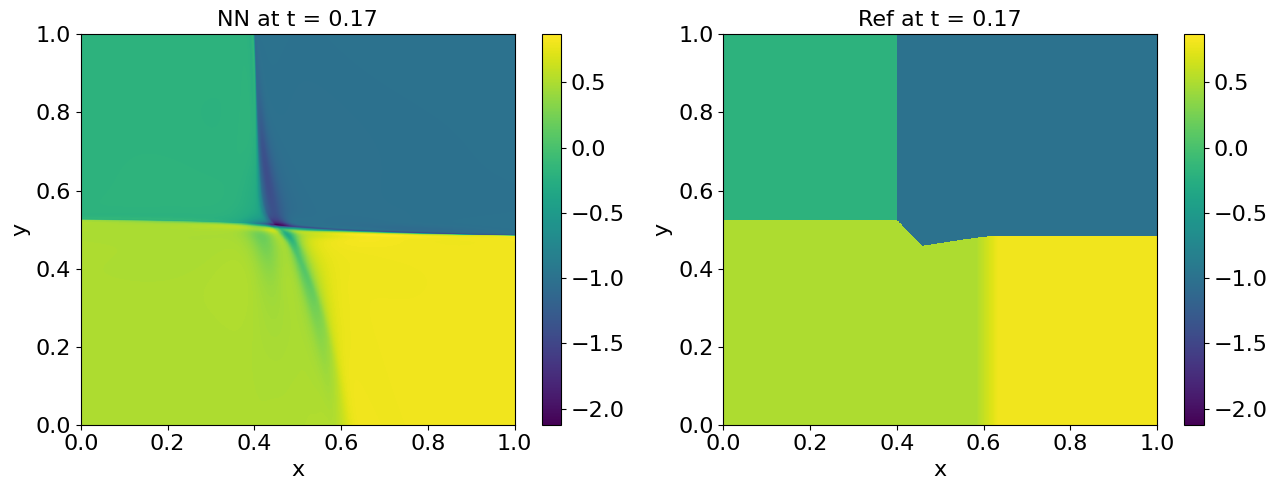

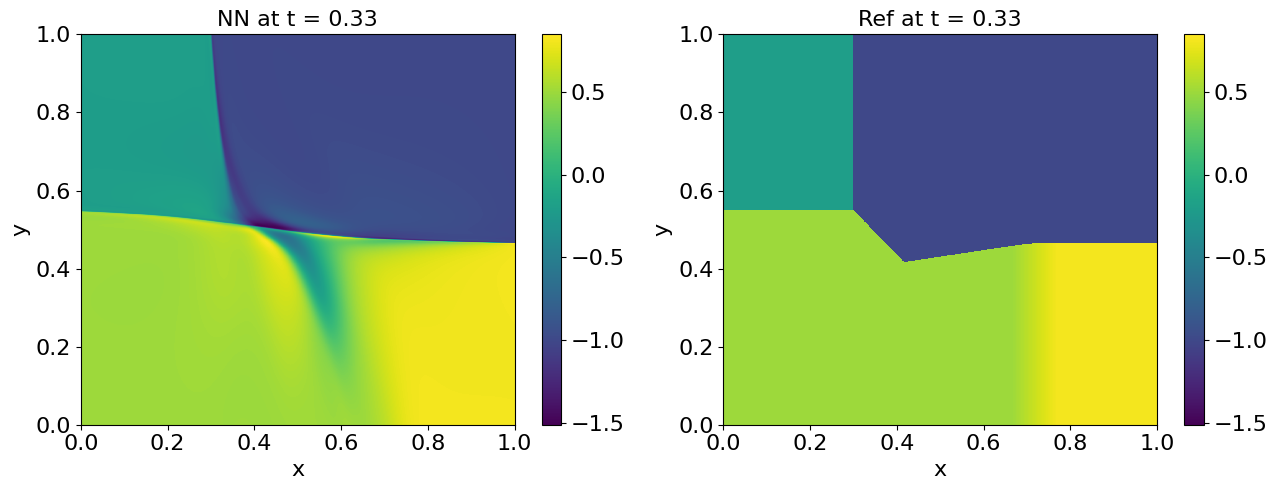

Grade 0, Iter 4100, loss_eqn: 0.000033, loss_ibc: 0.000743
Grade 0, Iter 4200, loss_eqn: 0.000033, loss_ibc: 0.000709
Grade 0, Iter 4300, loss_eqn: 0.000033, loss_ibc: 0.000697
Grade 0, Iter 4400, loss_eqn: 0.000032, loss_ibc: 0.000665
Grade 0, Iter 4500, loss_eqn: 0.000032, loss_ibc: 0.000686
Grade 0, Iter 4600, loss_eqn: 0.000032, loss_ibc: 0.000631
Grade 0, Iter 4700, loss_eqn: 0.000032, loss_ibc: 0.000607
Grade 0, Iter 4800, loss_eqn: 0.000032, loss_ibc: 0.000565
Grade 0, Iter 4900, loss_eqn: 0.000032, loss_ibc: 0.000563
Grade 0, Iter 5000, loss_eqn: 0.000031, loss_ibc: 0.000532


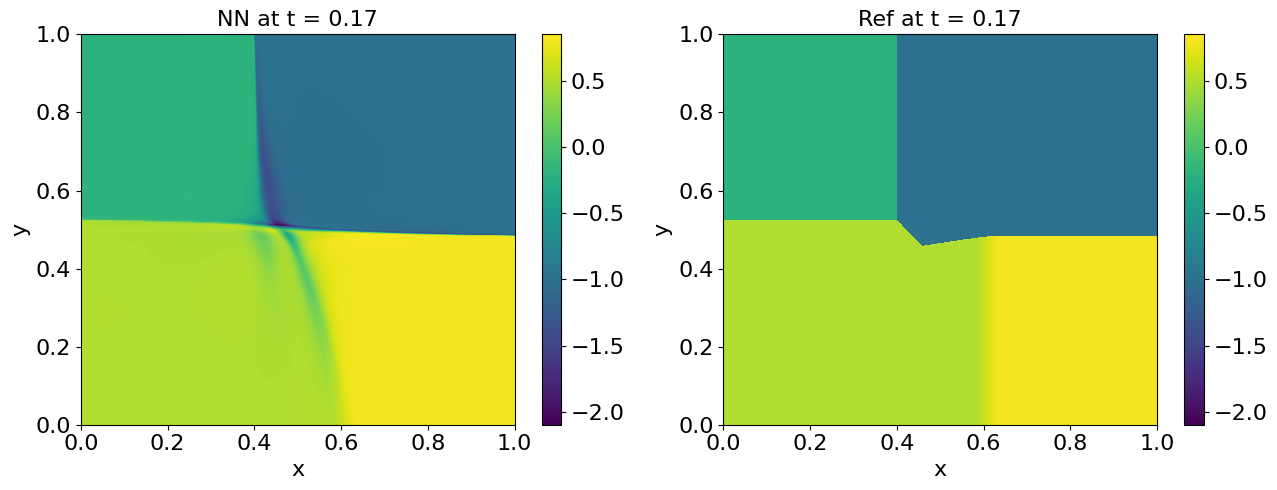

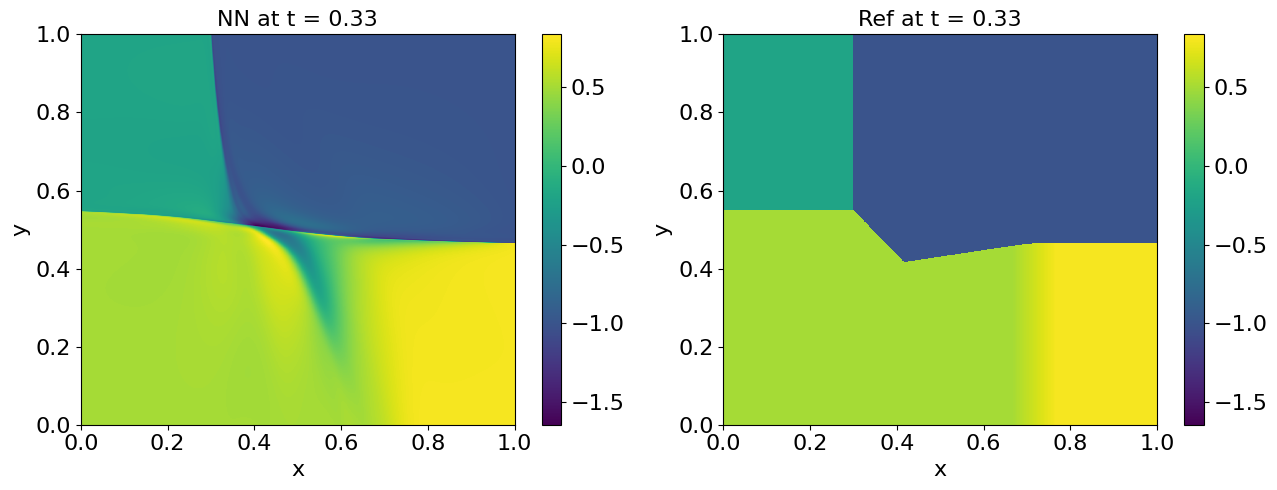

Grade 0, Iter 5100, loss_eqn: 0.000031, loss_ibc: 0.000510
Grade 0, Iter 5200, loss_eqn: 0.000031, loss_ibc: 0.000534
Grade 0, Iter 5300, loss_eqn: 0.000031, loss_ibc: 0.000475
Grade 0, Iter 5400, loss_eqn: 0.000031, loss_ibc: 0.000453
Grade 0, Iter 5500, loss_eqn: 0.000030, loss_ibc: 0.000439
Grade 0, Iter 5600, loss_eqn: 0.000030, loss_ibc: 0.000430
Grade 0, Iter 5700, loss_eqn: 0.000030, loss_ibc: 0.000423
Grade 0, Iter 5800, loss_eqn: 0.000030, loss_ibc: 0.000388
Grade 0, Iter 5900, loss_eqn: 0.000030, loss_ibc: 0.000377
Grade 0, Iter 6000, lambda_ic: 57.361740, lambda_bc: 22.017962, lambda_eqn: 4.991272
Grade 0, Iter 6000, loss_eqn: 0.000029, loss_ibc: 0.000377


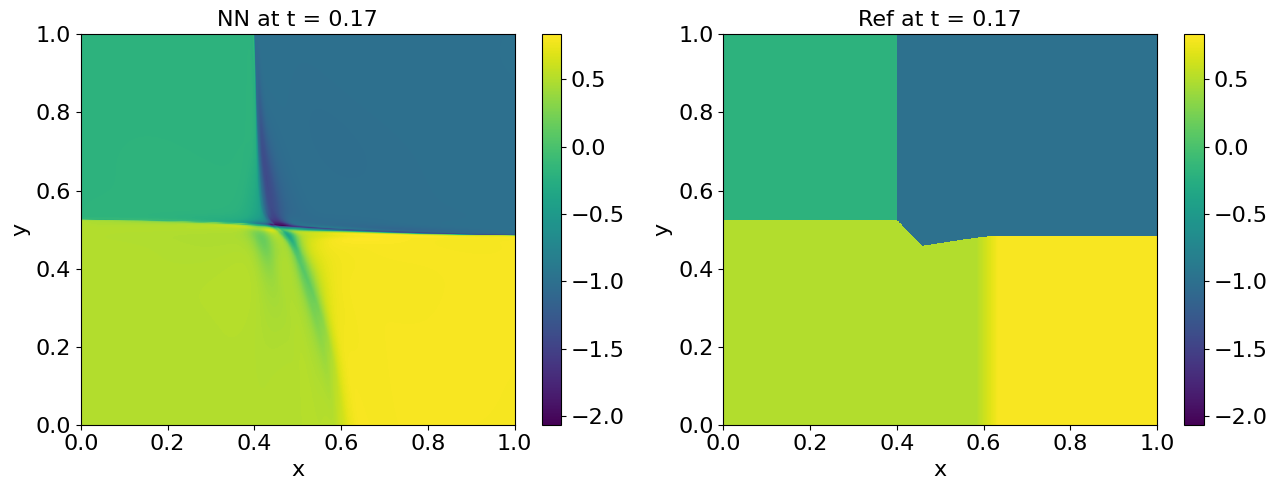

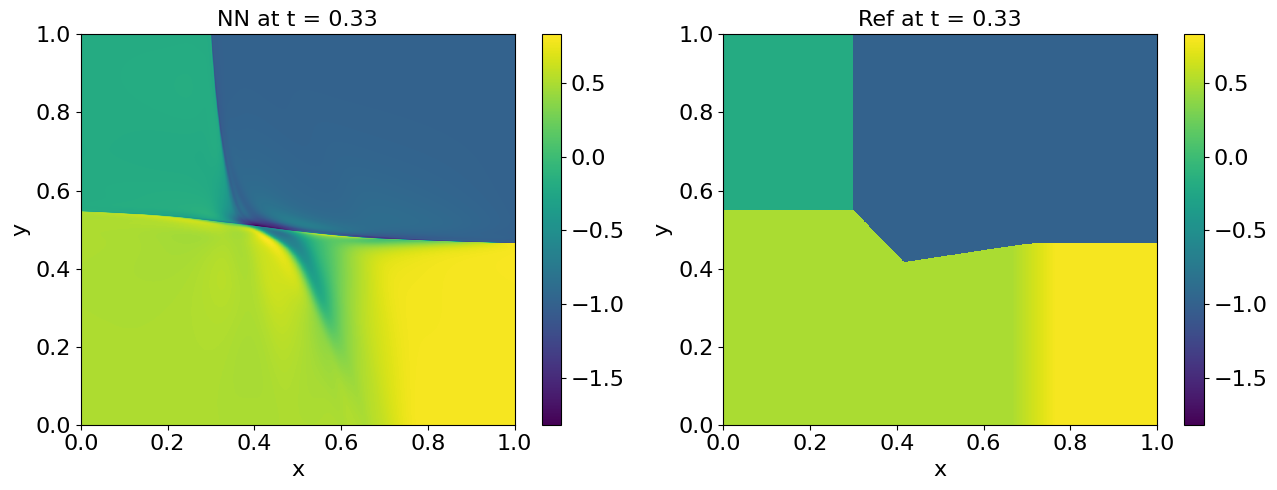

Grade 0, Iter 6100, loss_eqn: 0.000029, loss_ibc: 0.000371


In [ ]:
optprob.train_seq()

In [ ]:
def plot_u_theta_mesh(model, params=None, M_t=1000, M_x=2000, t_min=0.0, t_max=0.5, x_min=-1.0, x_max=1.0, y_min=None, y_max=None, M_y=None, ts=None, upload_fig=False, pwp=None, vals=None):
    """
    Plot the neural network function u_theta over a specified domain [t_min, t_max] x [x_min, x_max].
    Optionally overlay the mesh from PiecewiseLinearPolynomials and denote vals on the meshes.
    The 1D plot at t = t_max is removed, and only the 2D plot is shown.

    Args:
        model: Neural network u_theta.
        params: Parameters (pytree) of the neural network.
        M_t: Number of grid points in the t-direction (default: 1000).
        M_x: Number of grid points in the x-direction (default: 2000).
        t_min: Minimum value for t (default: 0.0).
        t_max: Maximum value for t (default: 0.5).
        x_min: Minimum value for x (default: -1.0).
        x_max: Maximum value for x (default: 1.0).
        y_min: Minimum value for y (for 3D cases, default: None).
        y_max: Maximum value for y (for 3D cases, default: None).
        M_y: Number of grid points in the y-direction (for 3D cases, default: None, falls back to M_x).
        ts: List or array of timestamps for which to plot individual 1D snapshots (default: None).
        upload_fig: Whether to upload the figure to wandb (default: False).
        pwp: Instance of PiecewiseLinearPolynomials(Tri/Rect/Hex/Tetra) to plot the mesh (default: None).
        vals: Values to denote on each mesh (default: None).
    """
    if ts is None:
        ts = []

    input_dim = model.input_dim if hasattr(model, 'input_dim') else 2
    if M_y is None:
        M_y = M_x

    if input_dim == 2:
        # Create a grid for t and x over the specified ranges
        t_grid = np.linspace(t_min, t_max, M_t)
        x_grid = np.linspace(x_min, x_max, M_x)
        t, x = np.meshgrid(t_grid, x_grid, indexing='ij')  # Shapes: (M_t, M_x)

        # Flatten the grid for batch evaluation
        tx_points = np.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (M_t * M_x, 2)

        # Evaluate u_theta on the grid points
        if params is None:
            u_values = model.forward(tx_points)
        else:
            u_values = model.forward_with_params(params, tx_points) if hasattr(model, 'forward_with_params') else model(params, tx_points)
        u_values = u_values.reshape(M_t, M_x)  # Reshape to (M_t, M_x)

        # Create larger figure for the 2D plot
        t_range = t_max - t_min
        fig = plt.figure(figsize=(20, 8 + 8 * t_range))
        ax1 = fig.add_subplot(111)

        # 2D color mesh plot
        pcm = ax1.pcolormesh(x_grid, t_grid, u_values, shading='nearest', cmap='viridis')
        fig.colorbar(pcm, ax=ax1)
        ax1.set_xlabel('x')
        ax1.set_ylabel('t')
        ax1.set_title('Neural Network Function $u_\\theta$')

        # Overlay the mesh and denote vals if pwp and vals are provided
        if pwp is not None:
            if isinstance(pwp, PiecewiseLinearPolynomialsTri):
                triangles = pwp.partitions
                for idx, tri in enumerate(triangles):
                    # Plot the three edges of the triangle
                    ax1.plot([tri[0][1], tri[1][1]], [tri[0][0], tri[1][0]], color='black', alpha=0.5, linewidth=0.5)
                    ax1.plot([tri[1][1], tri[2][1]], [tri[1][0], tri[2][0]], color='black', alpha=0.5, linewidth=0.5)
                    ax1.plot([tri[2][1], tri[0][1]], [tri[2][0], tri[0][0]], color='black', alpha=0.5, linewidth=0.5)
                    center = np.mean(tri, axis=0)
                    if vals is not None:
                        # Denote avg_val at the center
                        ax1.text(center[1], center[0], f'{vals[idx]:.2f}', fontsize=6, color='black', ha='center', va='center')

            elif isinstance(pwp, PiecewiseLinearPolynomialsRect):
                rectangles = pwp.partitions
                for idx, rect in enumerate(rectangles):
                    # Plot the four edges of the rectangle
                    ax1.plot([rect[0][1], rect[1][1]], [rect[0][0], rect[1][0]], color='black', alpha=0.5, linewidth=0.5)  # Bottom
                    ax1.plot([rect[0][1], rect[2][1]], [rect[0][0], rect[2][0]], color='black', alpha=0.5, linewidth=0.5)  # Left
                    ax1.plot([rect[2][1], rect[3][1]], [rect[2][0], rect[3][0]], color='black', alpha=0.5, linewidth=0.5)  # Top
                    ax1.plot([rect[3][1], rect[1][1]], [rect[3][0], rect[1][0]], color='black', alpha=0.5, linewidth=0.5)  # Right
                    center = np.mean(rect, axis=0)
                    if vals is not None:
                        # Denote avg_val at the center
                        ax1.text(center[1], center[0], f'{vals[idx]:.2f}', fontsize=6, color='black', ha='center', va='center')

        # Adjust layout and display the main plot
        plt.tight_layout()
        # Upload the main figure to wandb
        if upload_fig:
            wandb.log({f"u_theta_tmin{t_min:.1f}_tmax_{t_max:.1f}": wandb.Image(fig)})
        plt.show()

    elif input_dim == 3:
        if y_min is None or y_max is None:
            raise ValueError("For input_dim=3, y_min and y_max must be provided.")

        # 2D plot at t = t_max over (x, y)
        x_grid = np.linspace(x_min, x_max, M_x)
        y_grid = np.linspace(y_min, y_max, M_y)
        x, y = np.meshgrid(x_grid, y_grid)  # Shapes: (M_x, M_y)
        
        t = t_max * np.ones_like(x)
        txy_points = np.stack([t.ravel(), x.ravel(), y.ravel()], axis=1)  # Shape: (M_x * M_y, 3)
        
        # Evaluate u_theta on the grid points
        if params is None:
            u_values = model.forward(txy_points)
        else:
            u_values = model.forward_with_params(params, txy_points) if hasattr(model, 'forward_with_params') else model(params, txy_points)
        u_values = u_values.reshape(M_y, M_x)  # Reshape to (M_x, M_y)
        
        # Create figure for the 2D plot at t_max
        fig = plt.figure(figsize=(10, 8))
        ax1 = fig.add_subplot(111)
        
        # 2D color mesh plot
        pcm = ax1.pcolormesh(x_grid, y_grid, u_values, shading='nearest', cmap='viridis')
        fig.colorbar(pcm, ax=ax1)
        ax1.set_xlabel('x')
        ax1.set_ylabel('y')
        ax1.set_title(f'Neural Network Function $u_\\theta$ at t = {t_max:.2f}')
        
        # Overlay the mesh and denote vals for elements sharing a face with t = t_max
        
        if pwp is not None:
            partitions = pwp.partitions
            # Find elements that share a face with t = t_max (i.e., max t == t_max)
            max_t_per_elem = np.max(partitions[:, :, 0], axis=1)
            surface_mask = np.isclose(max_t_per_elem, t_max, atol=1e-6)
            surface_elems = partitions[surface_mask]
            surface_indices = np.where(surface_mask)[0]
            
            if isinstance(pwp, PiecewiseLinearPolynomialsHex):
                
                for i, hex_elem in enumerate(surface_elems):
                    # Find vertices at t = t_max (top face)
                    top_mask = np.isclose(hex_elem[:, 0], t_max, atol=1e-6)
                    top_verts = hex_elem[top_mask]
                    if len(top_verts) == 4:  # Expected for hex top face
                        x_top = top_verts[:, 1]
                        y_top = top_verts[:, 2]
                        # Order for closed rectangle: assuming vertices [lowx lowy, lowx highy, highx lowy, highx highy]
                        # Indices based on binary order: 0: lowx lowy, 1: lowx highy, 2: highx lowy, 3: highx highy
                        indices = np.array([0, 1, 3, 2])
                        ax1.plot(np.append(x_top[indices], x_top[indices[0]]), np.append(y_top[indices], y_top[indices[0]]), 
                                 color='black', alpha=0.5, linewidth=0.5)
                        
                        center_x = np.mean(x_top)
                        center_y = np.mean(y_top)
                        if vals is not None:
                            ax1.text(center_x, center_y, f'{vals[surface_indices[i]]:.2f}', fontsize=6, color='black', ha='center', va='center')
            
            elif isinstance(pwp, PiecewiseLinearPolynomialsTetra):
                for i, tet in enumerate(surface_elems):
                    # Find vertices at t = t_max
                    top_mask = np.isclose(tet[:, 0], t_max, atol=1e-6)
                    top_verts = tet[top_mask]
                    if len(top_verts) == 3:  # Triangle face
                        x_top = top_verts[:, 1]
                        y_top = top_verts[:, 2]
                        ax1.plot(np.append(x_top, x_top[0]), np.append(y_top, y_top[0]), 
                                 color='black', alpha=0.5, linewidth=0.5)
                        
                        center_x = np.mean(x_top)
                        center_y = np.mean(y_top)
                        if vals is not None:
                            ax1.text(center_x, center_y, f'{vals[surface_indices[i]]:.2f}', fontsize=6, color='black', ha='center', va='center')
            else:
                print("No such class!!!")
        plt.tight_layout()
        # Upload the figure to wandb
        if upload_fig:
            wandb.log({f"u_theta_at_tmax_{t_max:.1f}": wandb.Image(fig)})
        plt.show()

    # Plot separate figures for each timestamp in ts (adapted for dimension)
    for t_val in ts:
        if input_dim == 2:
            # Find the closest index in t_grid
            idx = np.argmin(np.abs(t_grid - t_val))
            # Create a new figure for the snapshot
            fig, ax = plt.subplots(1, 1, figsize=(10, 4))
            ax.plot(x_grid, u_values[idx, :])
            ax.set_xlabel('x')
            ax.set_ylabel('$u_\\theta(t, x)$')
            ax.set_title(f'Neural Network Function at t = {t_val:.2f} (closest t = {t_grid[idx]:.2f})')
            plt.tight_layout()
            plt.show()
        elif input_dim == 3:
            # Similar to t_max plot but without mesh/vals (or adapt if needed)
            x, y = np.meshgrid(x_grid, y_grid)
            t = t_val * np.ones_like(x)
            txy_points = np.stack([t.ravel(), x.ravel(), y.ravel()], axis=1)
            u_values_ts = model.forward(txy_points).reshape(M_y, M_x)
            fig_ts, ax_ts = plt.subplots(1, 1, figsize=(10, 8))
            pcm_ts = ax_ts.pcolormesh(x_grid, y_grid, u_values_ts, shading='nearest', cmap='viridis')
            fig_ts.colorbar(pcm_ts, ax=ax_ts)
            ax_ts.set_xlabel('x')
            ax_ts.set_ylabel('y')
            ax_ts.set_title(f'Neural Network Function $u_\\theta$ at t = {t_val:.2f}')
            plt.tight_layout()
            plt.show()

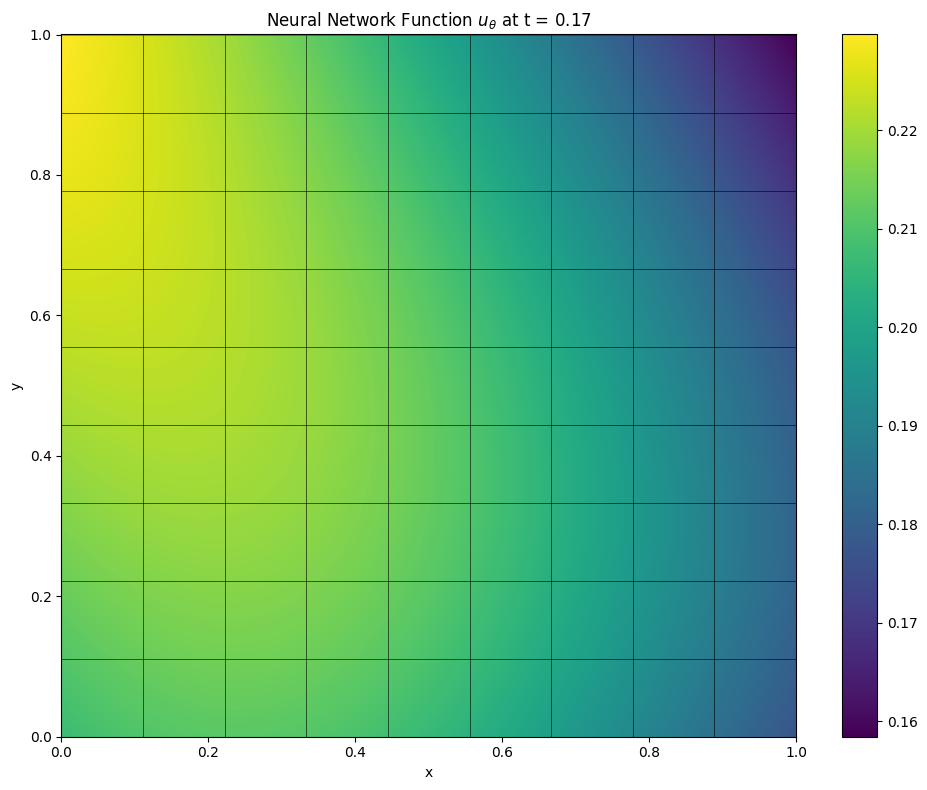

In [7]:
self = optprob.segments[0]
plot_u_theta_mesh(self.model, t_min=self.t_min, t_max=self.t_max, x_min=self.x_min,
                            x_max=self.x_max, y_min=0, y_max=1, pwp=self.pwp)

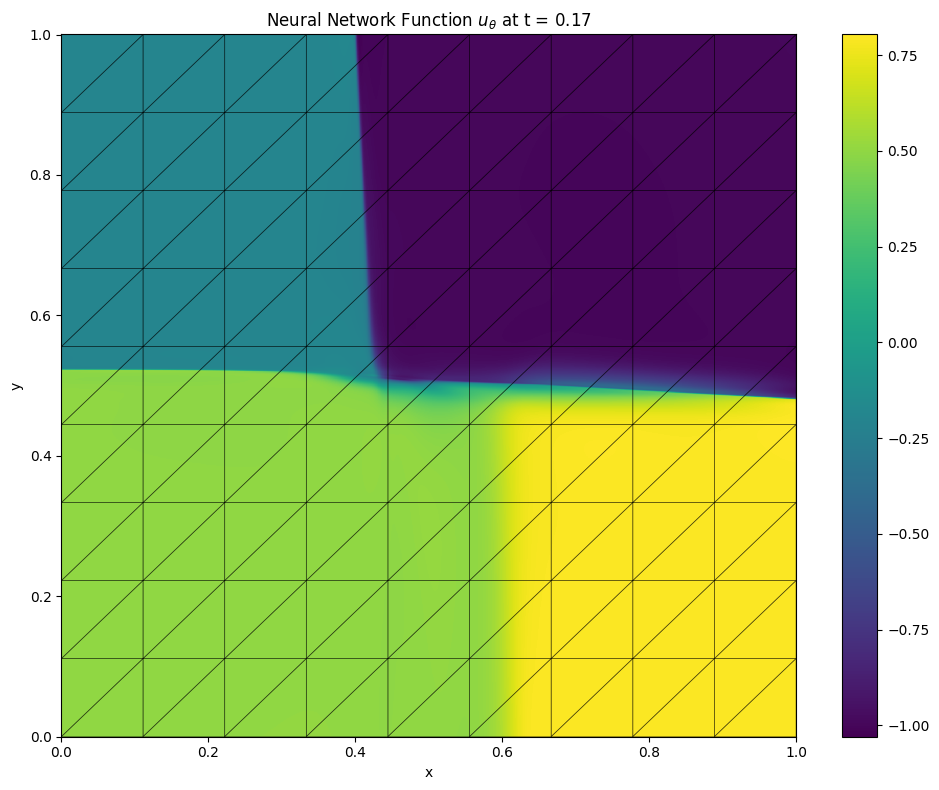

In [37]:
self = optprob.segments[0]
plot_u_theta_mesh(self.model, t_min=self.t_min, t_max=self.t_max, x_min=self.x_min,
                            x_max=self.x_max, y_min=0, y_max=1, pwp=self.pwp)

In [12]:
import numpy as np

def u_ref(t, x, y):
    """
    Reference solution u(t, x, y).
    Returns 0 if y > 0.5 + 0.5*t, else 1.
    """
    return np.where(y > 0.5 + 0.5 * t, 0, 1)

def u0(x, y):
    """
    Initial condition u0(x, y) = u(0, x, y).
    """
    return u_ref(t_min*np.zeros_like(x), x, y)

def u_left(t, y):
    """
    Boundary condition at x = x_min (independent of x, so same as u_ref).
    """
    return u_ref(t, np.zeros_like(y), y)  # x=0 as placeholder, since independent of x

def u_right(t, y):
    """
    Boundary condition at x = x_max (independent of x, so same as u_ref).
    """
    return u_ref(t, np.zeros_like(y), y)  # x=0 as placeholder

def u_bottom(t, x):
    """
    Boundary condition at y = y_min (independent of x, so same as u_ref with y=y_min).
    """
    return u_ref(t, x, np.zeros_like(x))  # y=0 as placeholder, but function needs y

def u_top(t, x):
    """
    Boundary condition at y = y_max (independent of x, so same as u_ref with y=y_max).
    """
    return u_ref(t, x, np.ones_like(x))  # y=0 as placeholder, adjust if y_max known

def res(u_quad, u_t, u_x, u_y):
    return u_t + u_quad * u_x + u_quad * u_y

In [13]:
t_min = 0
t_max = 0.5
x_min = 0
x_max = 1
y_min = 0
y_max = 1
N_t = 8
N_x = 9
N_y = 9
optprob = SeqMinMaxOptProb(input_dim=3, total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
    N_t=N_t, N_x=N_x, N_y=N_y, N_bc=128, N_ic=128,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_adaptive_weight=2000, f_opt_kh=1,
    u0=u0, u1=u_left, u2=u_right, u3=u_bottom, u4=u_top, project="seq_minmax_burgers2D",
    lambda_ic=20.0, lambda_bc=20.0, lambda_eqn=1.0,
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes='', pre_epochs=0,
    init_lrs=[2e-4, 1e-3, 1e-3], grade_epochs=[101, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, loss_type='interior', k=0, f_plot=2000, partition='hex', u_ref=u_ref,
    set_wandb=False
)

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.0000, 0.5000]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 9.413791
Grade 0, Iter 0, lambda_ic: 18.335306, lambda_bc: 18.339373, lambda_eqn: 1.145638
Grade 0, Iter 0, loss_eqn: 0.410825, loss_eqn_from_kh: 0.410592, loss_l1: 0.410592, loss_ibc: 3.018623


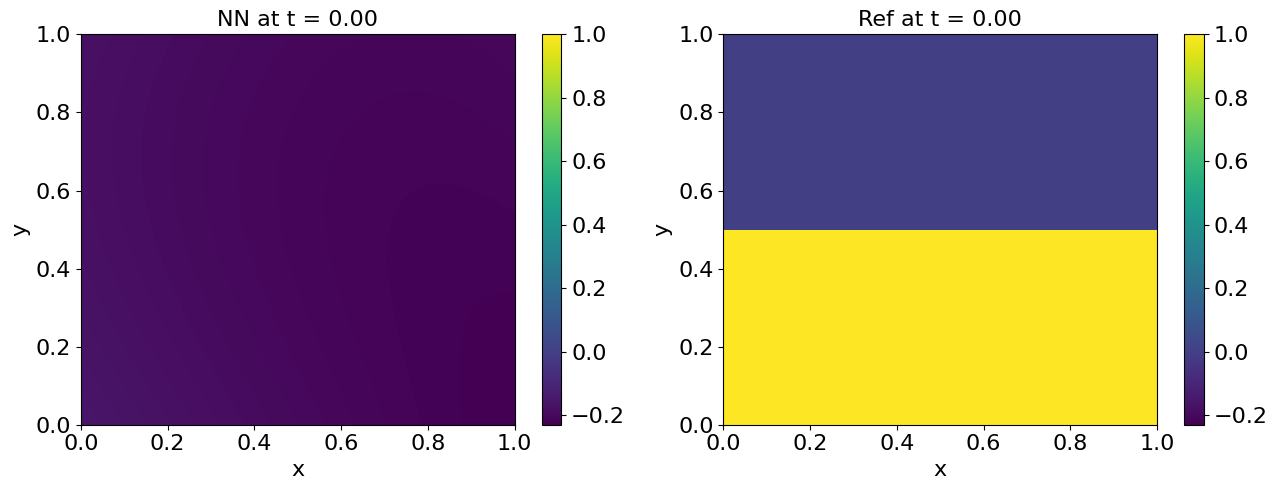

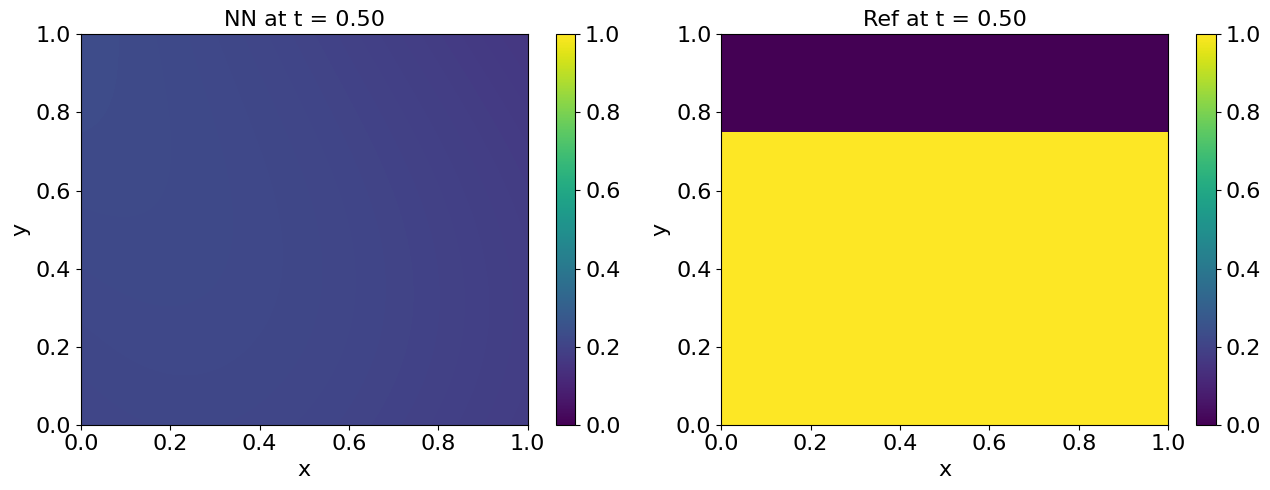

Grade 0, Iter 100, loss_eqn: 0.234396, loss_eqn_from_kh: 0.234049, loss_l1: 0.234049, loss_ibc: 0.275619
Train time for stage1: 92.617730 seconds

Plotting after training segment [0.0000, 0.5000]


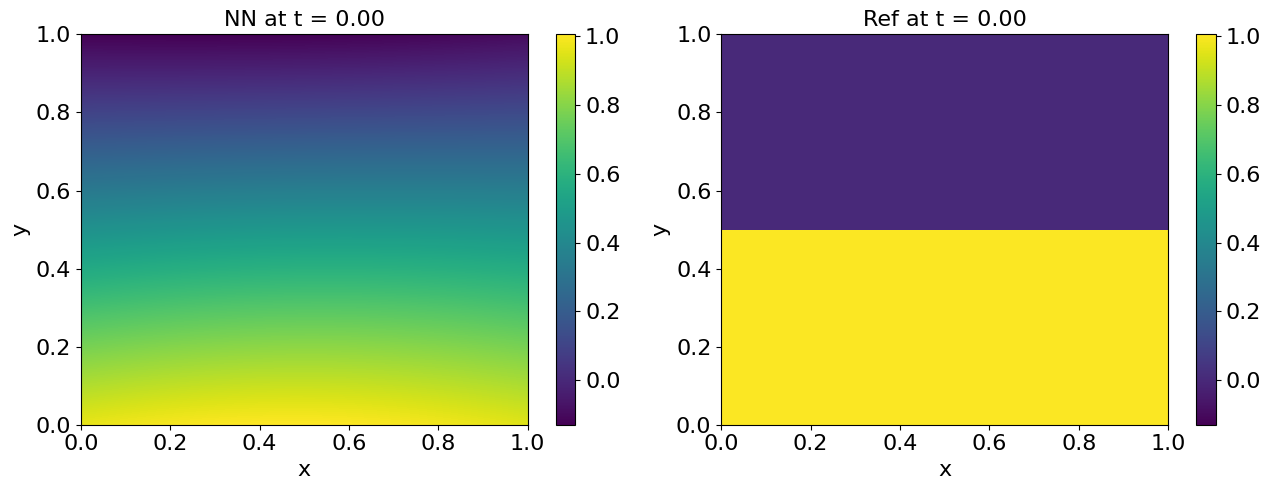

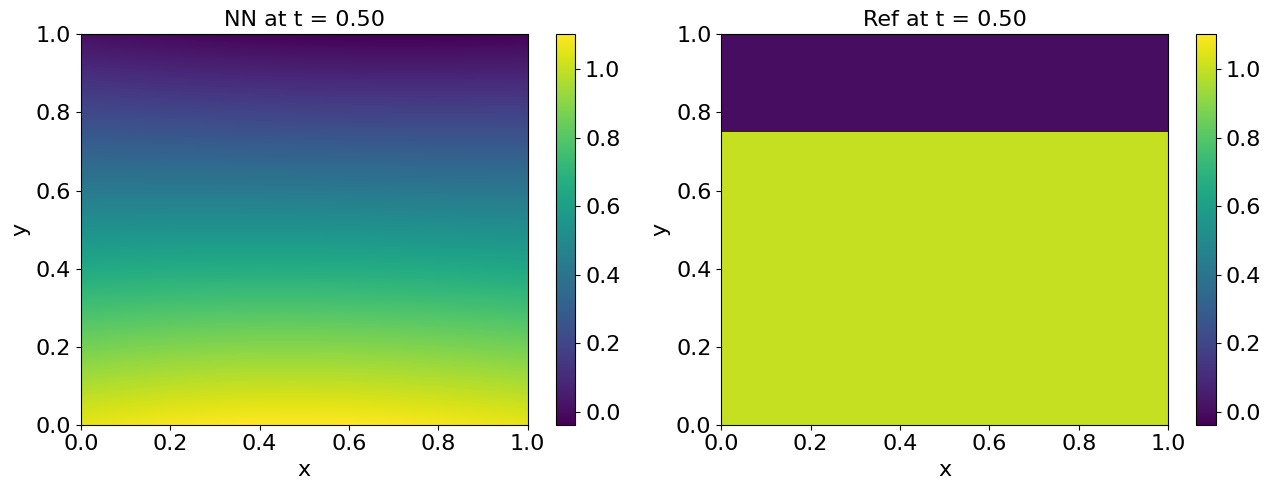

In [14]:
optprob.train_seq()

In [7]:
self = optprob.segments[0]
self.input_dim
self.u_ref(0.5, 1, 0.5)

IndexError: list index out of range

In [ ]:
plot_u_2D([0, 0.5], u_ref, nx=1000, ny=1000)

In [8]:
self = optprob
params = optprob.model.mlps[0].params
self.gen_funcs(0)
self.pwp.coeffs, self.key, loss_eqn_from_kh, loss_l1, loss_each_elem = self.maximize_kh_step(params, self.key)

In [9]:
Nt = self.pwp.N_elements
quad_points = self.pwp.quad_points_parti
u_values_all = self.u_eval(params, quad_points)
quad_weights = self.pwp.quad_weights_parti
avg_vals = jnp.einsum('ij,ij->i', u_values_all, quad_weights)/self.elem_meas
init_coeffs_all = jnp.hstack([avg_vals[..., None] , jnp.zeros((Nt, self.p_dof - 1))])
perturbations_all = self.sigma * jax.random.uniform(self.key, (self.N_perturb, self.p_dof), minval=-1, maxval=1)
perturbed_coeffs_all = init_coeffs_all[:, None, :] + perturbations_all[None, :, :]

In [35]:
parti_idx = 0
quad_points = self.pwp.quad_points_parti[parti_idx]
quad_weights = self.pwp.quad_weights_parti[parti_idx]
u_quad = self.u_eval(params, quad_points)
grad_u_tx = self.grad_u(params, quad_points)

In [36]:
quad_points.shape

(64, 3)

In [11]:
u_t, u_x, u_y = grad_u_tx[:, 0], grad_u_tx[:, 1], grad_u_tx[:, 2]
residual = self.res(u_quad, u_t, u_x, u_y).flatten()
p_coeffs_all = perturbed_coeffs_all[parti_idx]
k_h_quad_all = (p_coeffs_all[:, 0][:, None] + 
                p_coeffs_all[:, 1][:, None] * quad_points[:, 0] + 
                p_coeffs_all[:, 2][:, None] * quad_points[:, 1] + 
                p_coeffs_all[:, 3][:, None] * quad_points[:, 2]
               )
k_h_quad_all1 = jnp.einsum('ik,kj->ij', p_coeffs_all[:, 1:], quad_points.T) + p_coeffs_all[:, 0][:, None]

In [12]:
jnp.min(k_h_quad_all1-k_h_quad_all)

Array(-9.536743e-07, dtype=float32)

In [33]:
quad_points = self.pwp.quad_points
p_coeffs_quad = self.pwp.coeffs[self.pwp.element_indices]
k_h_quad = p_coeffs_quad[:, 0] + jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1)
k_h_quad1 = jnp.einsum('ij, ij->i', p_coeffs_quad[:, 1:], quad_points) + p_coeffs_quad[:, 0]

In [34]:
jnp.max(jnp.abs(k_h_quad-k_h_quad1))

Array(0., dtype=float32)

In [ ]:
jnp.max(k_h_quad-k_h_quad1)

In [28]:
jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1).shape

(41472,)

In [37]:
self.pwp.quad_points.shape

(41472, 3)

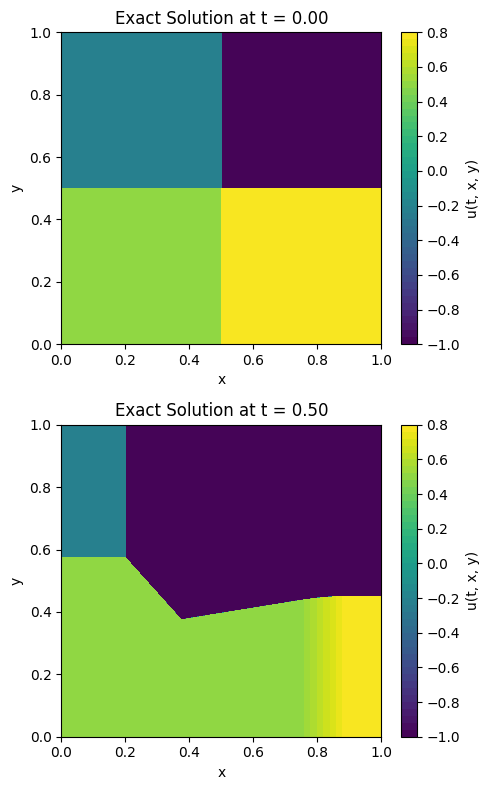

In [12]:
plot_u_2D([0, 0.5], u_ref, nx=1000, ny=1000)

In [77]:
N_t = 10  # Divisions in t
N_x = 5  # Divisions in x
N_y = 2  # Divisions in y
t_min = 0.0
t_max = 1
x_min = -1.0
x_max = 1.0
y_min = 0.0
y_max = 2.0

tau = (t_max - t_min) / N_t
hx = (x_max - x_min) / N_x
hy = (y_max - y_min) / N_y
t_starts = jnp.linspace(t_min, t_max - tau, N_t)
x_starts = jnp.linspace(x_min, x_max - hx, N_x)
y_starts = jnp.linspace(y_min, y_max - hy, N_y)
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
# Define the 8 vertices for each hexahedron using binary offsets
offsets_bin = jnp.array([[int(b) for b in f'{i:03b}'] for i in range(8)], dtype=jnp.float32)  # (8,3) binary 000 to 111
deltas = jnp.array([tau, hx, hy])
offsets = offsets_bin * deltas  # (8,3)
lowers = jnp.stack([tl.ravel(), xl.ravel(), yl.ravel()], axis=1)[:, None, :]  # (N_elements, 1, 3)
partitions = lowers + offsets[None, :, :]  # (N_elements, 8, 3)

In [83]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts)
xl.shape

(5, 10, 2)

In [69]:
# Gauss-Legendre nodes and weights in [-1, 1]
nodes, weights = np.polynomial.legendre.leggauss(3)
nodes_jnp = jnp.array(nodes)
weights_jnp = jnp.array(weights)

# Tensor product for 3D
t_nodes, x_nodes, y_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp, nodes_jnp)

In [79]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
tl.shape

(10, 5, 2)

In [72]:
t_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

In [73]:
x_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967]],

       [[ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ]],

       [[ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

Text(0.5, 1.0, 'Neural Network Function $u_\\theta$ at t = 1.00')

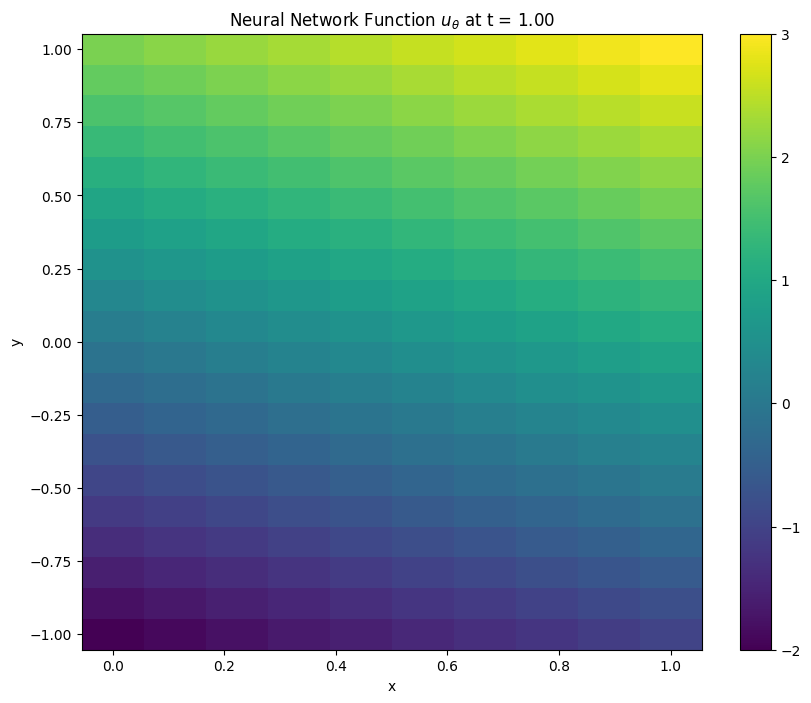

In [70]:
x_min = 0
x_max = 1
M_x = 10
y_min = -1
y_max = 1
M_y = 20
t_max = 1
# 2D plot at t = t_max over (x, y)
x_grid = np.linspace(x_min, x_max, M_x)
y_grid = np.linspace(y_min, y_max, M_y)
x, y = np.meshgrid(x_grid, y_grid, indexing='ij')  # Shapes: (M_x, M_y)
        
t = t_max * np.ones_like(x)
txy_points = np.stack([t.ravel(), x.ravel(), y.ravel()], axis=1)  # Shape: (M_x * M_y, 3)
        
# Evaluate u_theta on the grid points
u_values = txy_points[:,1]+2*txy_points[:,2]
u_values = u_values.reshape(x.shape)  # Reshape to (M_y, M_x)
        
# Create figure for the 2D plot at t_max
fig = plt.figure(figsize=(10, 8))
ax1 = fig.add_subplot(111)
        
# 2D color mesh plot
pcm = ax1.pcolormesh(x_grid, y_grid, u_values.T, shading='nearest', cmap='viridis')
fig.colorbar(pcm, ax=ax1)
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title(f'Neural Network Function $u_\\theta$ at t = {t_max:.2f}')

In [56]:
x_grid.shape

(10,)

In [54]:
x, y = np.meshgrid(x_grid, y_grid)

In [55]:
x.shape

(20, 10)

In [58]:
x, y = np.meshgrid(x_grid, y_grid, indexing='ij')

In [16]:
class PiecewiseLinearPolynomialsRect1:
    def __init__(self, N_t, N_x, t_min=0.0, t_max=1.0, x_min=-1.0, x_max=1.0, gauss_order=3, bdry_order=3, dg_type='Q1'):
        """
        Initialize a rectangular mesh with custom ranges.

        Args:
            N_t: Number of divisions along the t-axis.
            N_x: Number of divisions along the x-axis.
            t_min: Minimum value for t (default: 0.0).
            t_max: Maximum value for t (default: 1.0).
            x_min: Minimum value for x (default: -1.0).
            x_max: Maximum value for x (default: 1.0).
            gauss_order: Order of Gauss quadrature (number of points per direction, default: 2).
            bdry_order: Order of boundary quadrature (number of points per edge, default: 3).
        """
        self.N_t = N_t
        self.N_x = N_x
        self.t_min = t_min
        self.t_max = t_max
        self.x_min = x_min
        self.x_max = x_max
        self.gauss_order = gauss_order
        self.bdry_order = bdry_order
        self.N_elements = N_t * N_x  # Number of rectangles
        self.partitions = self._generate_rectangles()
        if dg_type == 'Q1':
            self.p_dof = 4
        elif dg_type == 'P1':
            self.p_dof = 3
        self.coeffs = jnp.zeros((self.N_elements, self.p_dof))  # Coefficients a, b, c for a + b*t + c*x per rectangle
        self.quad_points, self.quad_weights, self.quad_element_indices, self.quad_points_parti, self.quad_weights_parti = self._setup_quadrature()
        # self.bdry_points_parti, self.bdry_weights_parti = self.get_boundary_quadrature()
        # self.normals = self.compute_normals()

    def _generate_rectangles(self):
        """Generate the rectangles for the mesh with custom ranges."""
        self.ht = (self.t_max - self.t_min) / self.N_t  # Step size along t
        self.hx = (self.x_max - self.x_min) / self.N_x   # Step size along x

        t_starts = jnp.linspace(self.t_min, self.t_max - self.ht, self.N_t)
        x_starts = jnp.linspace(self.x_min, self.x_max - self.hx, self.N_x)
        tl, xl = jnp.meshgrid(t_starts, x_starts)
        # Define the 4 vertices for each hexahedron using binary offsets
        offsets_bin = jnp.array([[int(b) for b in f'{i:02b}'] for i in range(4)], dtype=jnp.float32)  # (4, 2) binary 00 to 11
        deltas = jnp.array([self.ht, self.hx])
        offsets = offsets_bin * deltas  # (4,2)
        lowers = jnp.stack([tl.ravel(), xl.ravel()], axis=1)[:, None, :]  # (N_elements, 1, 2)
        partitions = lowers + offsets[None, :, :]  # (N_elements, 4, 2)
        return partitions

    def _setup_quadrature(self):
        """
        Setup Gauss quadrature points and weights for rectangular mesh.

        Returns:
            quad_points: Quadrature points, shape (N_quad, 2).
            quad_weights: Quadrature weights, shape (N_quad,).
            quad_element_indices: Indices of rectangles, shape (N_quad,).
            quad_points_parti: Quadrature points per rectangle, shape (N_elements, self.Nq, 2).
            quad_weights_parti: Quadrature weights per rectangle, shape (N_elements, self.Nq).
        """
        self.Nq = self.gauss_order ** 2  # Number of quadrature points per rectangle

        # Gauss-Legendre nodes and weights in [-1, 1]
        nodes, weights = np.polynomial.legendre.leggauss(self.gauss_order)
        nodes_jnp = jnp.array(nodes)
        weights_jnp = jnp.array(weights)

        # Tensor product for 2D
        t_nodes, x_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp)
        t_weights, x_weights = jnp.meshgrid(weights_jnp, weights_jnp)
        quad_weights_2d = (t_weights * x_weights).ravel()

        # Function to map [-1,1]x[-1,1] to rectangle [t_low, t_high]x[x_low, x_high]
        def map_to_rect(rect):
            t_low, x_low = rect[0]
            t_high, x_high = rect[3]
            t_scale = (t_high - t_low) / 2
            x_scale = (x_high - x_low) / 2
            t_center = (t_high + t_low) / 2
            x_center = (x_high + x_low) / 2
            t_points = t_center + t_nodes.ravel() * t_scale
            x_points = x_center + x_nodes.ravel() * x_scale
            points = jnp.stack([t_points, x_points], axis=1)
            weights = quad_weights_2d * (t_scale * x_scale)
            return points, weights

        # Vectorize over rectangles
        quad_points_rect, quad_weights_rect = vmap(map_to_rect)(self.partitions)

        # Flatten for global quadrature
        quad_points = quad_points_rect.reshape(-1, 2)
        quad_weights = quad_weights_rect.reshape(-1)
        quad_element_indices = jnp.repeat(jnp.arange(self.N_elements), self.Nq)

        return quad_points, quad_weights, quad_element_indices, quad_points_rect, quad_weights_rect

In [87]:
import numpy as np
from scipy import integrate
from PwpTri_class import PiecewiseLinearPolynomialsTri

# Test parameters
t_min = -1.0/20
t_max = 1.9/20
x_min = -1.0/20
x_max = 1.0/20
N_t = 1
N_x = 1
rf_times = 2  # Refinement level, adjust as needed (0,1,2)

# Instantiate the class
mesh = PiecewiseLinearPolynomialsRect(N_t, N_x, t_min=t_min, t_max=t_max, x_min=x_min, x_max=x_max, rf_times=rf_times)
mesh1 = PiecewiseLinearPolynomialsRect1(N_t, N_x, t_min=t_min, t_max=t_max, x_min=x_min, x_max=x_max, gauss_order=rf_times)
mesh2 = PiecewiseLinearPolynomialsTri(N_t, N_x, t_min=t_min, t_max=t_max, x_min=x_min, x_max=x_max, rf_times=rf_times)

# Define a test function
def f(t, x):
    return np.sign(t) * (1+np.cos(1.2*x))  # Integrable function

# Compute integral using the class's quadrature
quad_points = mesh.quad_points
quad_weights = mesh.quad_weights
quad_points1 = mesh1.quad_points
quad_weights1 = mesh1.quad_weights
quad_points2 = mesh2.quad_points
quad_weights2 = mesh2.quad_weights
integral_quad = np.sum(f(quad_points[:, 0], quad_points[:, 1]) * quad_weights)
integral_quad1 = np.sum(f(quad_points1[:, 0], quad_points1[:, 1]) * quad_weights1)
integral_quad2 = np.sum(f(quad_points2[:, 0], quad_points2[:, 1]) * quad_weights2)

# Compute reference integral using scipy.integrate.dblquad
def integrand(x, t):  # Note: dblquad integrates dy dx, but here y=x, x=t? Wait, dblquad(func, a, b, gfun, hfun) where func(y, x)
    return f(t, x)  # Wait, dblquad integrates ∫_x=a^b ∫_y=g(x)^h(x) func(y,x) dy dx
# So to integrate ∫_t=tmin^tmax ∫_x=xmin^xmax f(t,x) dx dt, set as ∫_t=tmin^tmax ∫_x=xmin^xmax f(t,x) dx dt, so func(x, t) = f(t, x), but dblquad does inner dy (x) outer dx (t)
integral_ref, abserr = integrate.dblquad(lambda x, t: f(t, x), t_min, t_max, lambda t: x_min, lambda t: x_max)

print(f"Quadrature integral: {integral_quad}")
print(f"Reference integral (dblquad): {integral_ref}")
print(f"Absolute error estimate from dblquad: {abserr}")
print(f"Difference: {abs(integral_quad - integral_ref)}")
print(f"Difference: {abs(integral_ref - integral_quad1)}")
print(f"Difference: {abs(integral_ref - integral_quad2)}")

Quadrature integral: 0.007247553206980228
Reference integral (dblquad): 0.008997299119431167
Absolute error estimate from dblquad: 4.785764325716003e-09
Difference: 0.0017497455701231956
Difference: 0.008997298777103424
Difference: 0.0017497455701231956


In [61]:
np.max(mesh1.quad_points, axis=0)

Array([2.075833  , 0.57735026], dtype=float32)

In [62]:
quad_points.shape

(25, 2)

In [73]:
integral_ref

3.3146477701289916

In [79]:
integral_quad

Array(0.00724755, dtype=float32)

In [78]:
integral_quad1

Array(0., dtype=float32)

In [77]:
integral_ref

0.008997299119431167

In [83]:
N_t = 10
N_x = 15

t_low, x_low = (-1.0, 0.0)
t_high, x_high = (1.0, 1.0)
dt = (t_high - t_low) / N_t
dx = (x_high - x_low) / N_x
t_grid = jnp.linspace(t_low, t_high, N_t)
x_grid = jnp.linspace(x_low, x_high, N_x)
tt, xx = jnp.meshgrid(t_grid, x_grid, indexing='ij')
points = jnp.stack([tt.ravel(), xx.ravel()], axis=1)
wt = jnp.full(N_t, dt)
wt = wt.at[0].set(dt / 2)
wt = wt.at[-1].set(dt / 2)
wx = jnp.full(N_x, dx)
wx = wx.at[0].set(dx / 2)
wx = wx.at[-1].set(dx / 2)
weights_2d = wt[:, None] * wx[None, :]

In [84]:
tt.shape

(10, 15)

In [88]:
y_grid = jnp.linspace(-1, 1, 50)
tt, xx, yy = jnp.meshgrid(t_grid, x_grid, y_grid, indexing='ij')

In [6]:
jnp.array([1, *jnp.array([1, 1])])

Array([1, 1, 1], dtype=int32)